# SupeRR Selector Season 2 — Round 1: Most Reliable Players Under Pressure

*Rajasthan Royals data challenge · IPL + T20I ball-by-ball data, 2022 onwards (784 analysed matches, 187k deliveries)*

## Final answer (details and evidence in Sections 9-13)

| Rank | Top-10 **batters** under pressure | Top-10 **bowlers** under pressure |
|---|---|---|
| 1 | Dinesh Karthik | Sunil Narine |
| 2 | Heinrich Klaasen | Josh Hazlewood |
| 3 | Phil Salt | Jasprit Bumrah |
| 4 | Suryakumar Yadav | Abrar Ahmed |
| 5 | Shreyas Iyer | Sean Abbott |
| 6 | Tim David | Shaheen Afridi |
| 7 | Abhishek Sharma | Mujeeb Ur Rahman |
| 8 | Sikandar Raza | Nathan Ellis |
| 9 | Nicholas Pooran | Gudakesh Motie |
| 10 | Mohammad Nawaz | Mustafizur Rahman |

**One-line method.** Pressure = *leverage*: how much a delivery can swing a modelled win probability. Performance = runs (and wickets) above what the situation normally yields. Rating = pressure ability from a hierarchical shrinkage model (usual level + pressure uplift) + consistency across pressure appearances.



# 1. Problem, approach and roadmap

**Task (from the problem statement PDF).** Build a data-driven system that measures how batters and bowlers perform in *high-pressure* match situations compared with their usual levels, and rank the players who deliver most consistently when it matters. Pressure is ours to define; the method must work for both batting and bowling; the final deliverables are two ranked top-10 lists (batters, bowlers) plus a methodology report that covers: pressure definition, performance measurement, fair comparison, evidence and reliability/limitations.



**Data used (all six CSVs).** `ball_by_ball` (core), `matches` (results, venue, DLS flags, date), `competitions` (IPL / T20I tagging), `teams` (team names), `playing_eleven` (matches played, roles) and `competition_team_player_mapping` (canonical player names and teams).

In [22]:
import warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import HistGradientBoostingClassifier as HGBC, HistGradientBoostingRegressor as HGBR
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from scipy.stats import spearmanr
from scipy.optimize import minimize

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220); pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})

#configuration
SEED          = 7
CV_FOLDS      = 5
HP_PCT        = 0.75
LI_CAP        = 5.0
MIN_HP_BALLS  = 100
MIN_PA        = 15
MIN_PA_BALLS  = 4
SHRINK_MIN_N  = 60
BETA_K        = 10
WEIGHTS       = dict(level=0.60, resilience=0.15, consistency=0.25)
N_BOOT        = 300

# Google Drive mount
from google.colab import drive
drive.mount('/content/drive')

DRIVE_FOLDER = Path('/content/drive/MyDrive/SupeRR_Selector')

if (DRIVE_FOLDER / 'ball_by_ball.csv').exists():
    DATA_DIR = DRIVE_FOLDER
else:
    hits = list(Path('/content/drive/MyDrive').rglob('ball_by_ball.csv'))
    assert hits, ('ball_by_ball.csv not found in Drive. Upload all 6 CSVs to a folder and set DRIVE_FOLDER above.')
    DATA_DIR = hits[0].parent

required = ['ball_by_ball', 'matches', 'competitions', 'teams', 'playing_eleven', 'competition_team_player_mapping']
missing = [f for f in required if not (DATA_DIR / f'{f}.csv').exists()]
assert not missing, f'Missing CSV files in {DATA_DIR}: {missing}'


OUT_DIR = DATA_DIR / 'outputs'; OUT_DIR.mkdir(exist_ok=True)
print('data from  :', DATA_DIR)
print('outputs to :', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data from  : /content/drive/MyDrive/SupeRR_Selector
outputs to : /content/drive/MyDrive/SupeRR_Selector/outputs


# 2. Load the data and check its integrity

In [23]:
bbb  = pd.read_csv(DATA_DIR/'ball_by_ball.csv')
mt   = pd.read_csv(DATA_DIR/'matches.csv')
comp = pd.read_csv(DATA_DIR/'competitions.csv')
team = pd.read_csv(DATA_DIR/'teams.csv')
xi   = pd.read_csv(DATA_DIR/'playing_eleven.csv')
pmap = pd.read_csv(DATA_DIR/'competition_team_player_mapping.csv')

summary = pd.DataFrame({'file': ['ball_by_ball','matches','competitions','teams','playing_eleven','competition_team_player_mapping'],
                        'rows': [len(bbb), len(mt), len(comp), len(team), len(xi), len(pmap)],
                        'columns': [bbb.shape[1], mt.shape[1], comp.shape[1], team.shape[1], xi.shape[1], pmap.shape[1]],
                        'role in this analysis': ['delivery-level outcomes (runs, wickets, extras, striker/bowler, batting order, pace/spin)',
                                                  'result, winner, date, venue, stage, DLS-revision flags',
                                                  'IPL vs T20I tagging and season', 'team names', 'matches played, batting position, impact-player flags',
                                                  'canonical player names and teams']})
display(summary)

# integrity checks
comp['comp_type'] = np.where(comp.comp_name.str.startswith('IPL'), 'IPL', np.where(comp.match_format == 'T20I', 'T20I', 'Other'))
print('competitions by type:\n', comp.comp_type.value_counts().to_string())
print('\nballs whose match is missing from matches.csv :', (~bbb.match_id.isin(mt.match_id)).sum())
print('matches in matches.csv without ball data       :', (~mt.match_id.isin(bbb.match_id)).sum(), '(abandoned / no result)')
print('innings values in ball data                    :', bbb.innings.value_counts().to_dict(), ' (3-4 = super overs)')
print('players with >1 name in ball data              :', (bbb.groupby('striker_id').striker_name.nunique() > 1).sum())
print('players with >1 name in mapping                :', (pmap.groupby('player_id').player_name.nunique() > 1).sum())
print('\nmissing values in ball data (only columns with NaN):'); print(bbb.isna().sum()[lambda s: s > 0].to_string())

,file,rows,columns,role in this analysis
0,ball_by_ball,200999,33,"delivery-level outcomes (runs, wickets, extras..."
1,matches,883,22,"result, winner, date, venue, stage, DLS-revisi..."
2,competitions,141,4,IPL vs T20I tagging and season
3,teams,353,3,team names
4,playing_eleven,28381,9,"matches played, batting position, impact-playe..."
5,competition_team_player_mapping,6413,6,canonical player names and teams


competitions by type:
 comp_type
T20I     134
IPL        5
Other      2

balls whose match is missing from matches.csv : 0
matches in matches.csv without ball data       : 16 (abandoned / no result)
innings values in ball data                    : {1: 105727, 2: 95234, 3: 25, 4: 13}  (3-4 = super overs)
players with >1 name in ball data              : 0
players with >1 name in mapping                : 0

missing values in ball data (only columns with NaN):
dismissal_type_id      190118
dismissal_type         190118
dismissed_player_id    190107
extras_type            189167
stroke                   6158
delivery_style            391
over_or_around            407


# 3. Cleaning and ball-level definitions

Key conventions (verified against the data above):

* **Legal delivery** = not a wide and not a no-ball (`extras_type` in *wide*, *Overstep*, *other* are the illegal ones). Six legal deliveries per over was confirmed for ~99.4 % of completed overs; the rest are interrupted/short overs.
* **Runs on a delivery** = `runs` (off the bat) + `extras1_runs` + `extras_2_runs`. **Charged to the bowler** = bat runs + wides + no-balls (byes/leg-byes are not).
* **Batter faces** every delivery except wides. **Dismissal of the striker** = `is_wicket` with `dismissed_player_id == striker_id`, excluding *Retire Out*. **Bowler wicket** = caught, bowled, LBW, stumped, hit-wicket (run-outs are not credited to the bowler).
* **Excluded matches** (documented below): non-IPL/T20I competitions that slipped into the file (Emerging Teams Asia Cup, Rising Stars), rain-affected games with revised overs/targets (the pressure arithmetic of 20 vs 20 overs no longer holds), games with a super over (the regulation-time result is a tie so the label is ambiguous), and matches without a decisive winner.

In [24]:
b = bbb.copy()
b['extras_type'] = b.extras_type.fillna('None')
b['is_wide']   = b.extras_type.eq('wide')
b['is_noball'] = b.extras_type.isin(['Overstep', 'other'])
b['legal']     = ~(b.is_wide | b.is_noball)
b['total_runs']  = b.runs + b.extras1_runs + b.extras_2_runs
b['bowler_runs'] = b.runs + np.where(b.is_wide | b.is_noball, b.extras1_runs + b.extras_2_runs, 0)
b['bat_faced']   = ~b.is_wide
b['striker_out'] = b.is_wicket & (b.dismissed_player_id == b.striker_id) & (~b.dismissal_type.eq('Retire Out'))
b['bowler_wkt']  = b.is_wicket & b.dismissal_type.isin(['Caught', 'Bowled', 'LBW', 'Stump', 'Hit Wicket'])
b = b.sort_values(['match_id', 'innings', 'innings_ball_num']).reset_index(drop=True)

legal_per_over = b[b.innings <= 2].groupby(['match_id', 'innings', 'overid']).legal.sum()
print(f'overs with exactly 6 legal balls: {(legal_per_over == 6).mean():.1%}')

mt = mt.merge(comp[['comp_id', 'comp_name', 'comp_type', 'season']], on='comp_id', how='left')
mt['match_date'] = pd.to_datetime(mt.match_date)

# --- exclusion waterfall
have_balls  = mt[mt.match_id.isin(b.match_id)]
s1 = have_balls[have_balls.comp_type != 'Other']
revised = s1.first_inn_revised_overs.notna() | s1.second_inn_revised_overs.notna() | s1.revised_target.notna()
s2 = s1[~revised]
so_matches = b[b.innings > 2].match_id.unique()
s3 = s2[~s2.match_id.isin(so_matches)]
s4 = s3[s3.win_team_id.notna()]
wf = pd.DataFrame({'step': ['matches in matches.csv', 'with ball-by-ball data', 'IPL or T20I only', 'no DLS / revised overs', 'no super over', 'decisive result (kept)'],
                   'matches': [len(mt), len(have_balls), len(s1), len(s2), len(s3), len(s4)]})
wf['dropped'] = (-wf.matches.diff()).fillna(0).astype(int)
display(wf)
mm = s4.copy()
print(mm.comp_type.value_counts().to_dict(), '| seasons:', sorted(mm.match_date.dt.year.unique()))

overs with exactly 6 legal balls: 98.2%


,step,matches,dropped
0,matches in matches.csv,883,0
1,with ball-by-ball data,867,16
2,IPL or T20I only,837,30
3,no DLS / revised overs,803,34
4,no super over,799,4
5,decisive result (kept),784,15


{'T20I': 429, 'IPL': 355} | seasons: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


# 4. Match-state features

For every delivery we reconstruct the **state before the ball is bowled**: legal balls bowled/left, runs, wickets, target, runs needed and required rate (2nd innings). Two context signals are added so that pressure and performance are judged *fairly*:

* **Team strength (Elo).** A chronological Elo rating for every team (IPL franchises and national teams form separate pools because they never meet). Using *pre-match* ratings avoids look-ahead. `elo_diff` = batting team − bowling team.
* **Venue par.** Average first-innings total at the ground, estimated leave-one-match-out with shrinkage (so a match never sees its own score).

In [25]:
# ---- Elo (pre-match), chronological
mel = mt[mt.win_team_id.notna() & (mt.comp_type != 'Other')].sort_values(['match_date', 'match_id'])
elo, pre = {}, {}
for r in mel.itertuples():
    h, a, w = r.home_team_id, r.away_team_id, r.win_team_id
    eh, ea = elo.get(h, 1500.), elo.get(a, 1500.)
    pre[r.match_id] = (eh, ea)
    exp_h = 1 / (1 + 10 ** ((ea - eh) / 400)); sh = 1.0 if w == h else 0.0
    elo[h] = eh + 20 * (sh - exp_h); elo[a] = ea + 20 * ((1 - sh) - (1 - exp_h))
mm['home_elo'] = mm.match_id.map(lambda x: pre[x][0]); mm['away_elo'] = mm.match_id.map(lambda x: pre[x][1])

d = b[b.match_id.isin(mm.match_id)].copy()
d = d.merge(mm[['match_id', 'match_date', 'comp_type', 'comp_name', 'season', 'venue_id', 'venue_country', 'home_team_id', 'away_team_id',
                'home_elo', 'away_elo', 'win_team_id', 'stage', 'knock_out']], on='match_id')
home_bat = d.batting_team_id == d.home_team_id
d['bat_elo']  = np.where(home_bat, d.home_elo, d.away_elo)
d['bowl_elo'] = np.where(home_bat, d.away_elo, d.home_elo)
d['elo_diff'] = d.bat_elo - d.bowl_elo
d['is_ipl']   = (d.comp_type == 'IPL').astype(int)
d['bat_win']  = (d.win_team_id == d.batting_team_id).astype(int)

g = d.groupby(['match_id', 'innings'], sort=False)
d['legal_i'] = d.legal.astype(int)
d['wk_i']    = (d.is_wicket & ~d.dismissal_type.eq('Retire Out')).astype(int)
d['balls_bowled'] = g.legal_i.cumsum() - d.legal_i
d['runs_so_far']  = g.total_runs.cumsum() - d.total_runs
d['wkts']         = g.wk_i.cumsum() - d.wk_i
d['balls_left']   = 120 - d.balls_bowled
inn1_total = d[d.innings == 1].groupby('match_id').total_runs.sum().rename('inn1_total')
d = d.merge(inn1_total, on='match_id', how='left')
d['target']       = np.where(d.innings == 2, d.inn1_total + 1, np.nan)
d['runs_needed']  = d.target - d.runs_so_far
d['rrr']          = np.where(d.innings == 2, d.runs_needed * 6 / d.balls_left.clip(lower=1), np.nan)
d['phase']        = pd.cut(d.overid, [0, 6, 15, 20], labels=['Powerplay (1-6)', 'Middle (7-15)', 'Death (16-20)'])

# venue par, leave-one-match-out + shrinkage towards the global mean
v1 = d[d.innings == 1].groupby(['match_id', 'venue_id']).total_runs.sum().reset_index(name='t')
gm = v1.t.mean(); vs = v1.groupby('venue_id').t.agg(['sum', 'count']); v1 = v1.join(vs, on='venue_id')
v1['venue_par'] = ((v1['sum'] - v1.t) + 5 * gm) / ((v1['count'] - 1) + 5)
d = d.merge(v1[['match_id', 'venue_par']], on='match_id', how='left')
d = d.reset_index(drop=True)
print(f'analysis table: {len(d):,} deliveries | {d.match_id.nunique()} matches | {d.striker_id.nunique()} batters | {d.bowler_id.nunique()} bowlers')

tname = team.drop_duplicates('team_id').set_index('team_id').team_name
final_elo = pd.Series(elo).rename('elo').to_frame().assign(team=lambda x: x.index.map(tname))
final_elo['pool'] = np.where(final_elo.team.isin(mm[mm.comp_type == 'IPL'].home_team), 'IPL', 'T20I')
display(final_elo.sort_values('elo', ascending=False).groupby('pool').head(6).reset_index(drop=True))

analysis table: 187,142 deliveries | 784 matches | 815 batters | 587 bowlers


,elo,team,pool
0,"1,646.551",England,T20I
1,"1,638.572",India,T20I
2,"1,620.618",Australia,T20I
3,"1,590.053",Royal Challengers Bengaluru,IPL
4,"1,576.182",Pakistan,T20I
5,"1,551.677",Gujarat Titans,IPL
6,"1,525.588",New Zealand,T20I
7,"1,516.780",Sunrisers Hyderabad,IPL
8,"1,509.425",Kuwait,T20I
9,"1,504.828",Kolkata Knight Riders,IPL


# 5. Exploratory analysis: what does T20 scoring look like in this data?

The EDA answers the questions that shape the pressure definition: *where do runs and wickets come from, do chases behave differently from first innings, and do IPL and T20I differ?*

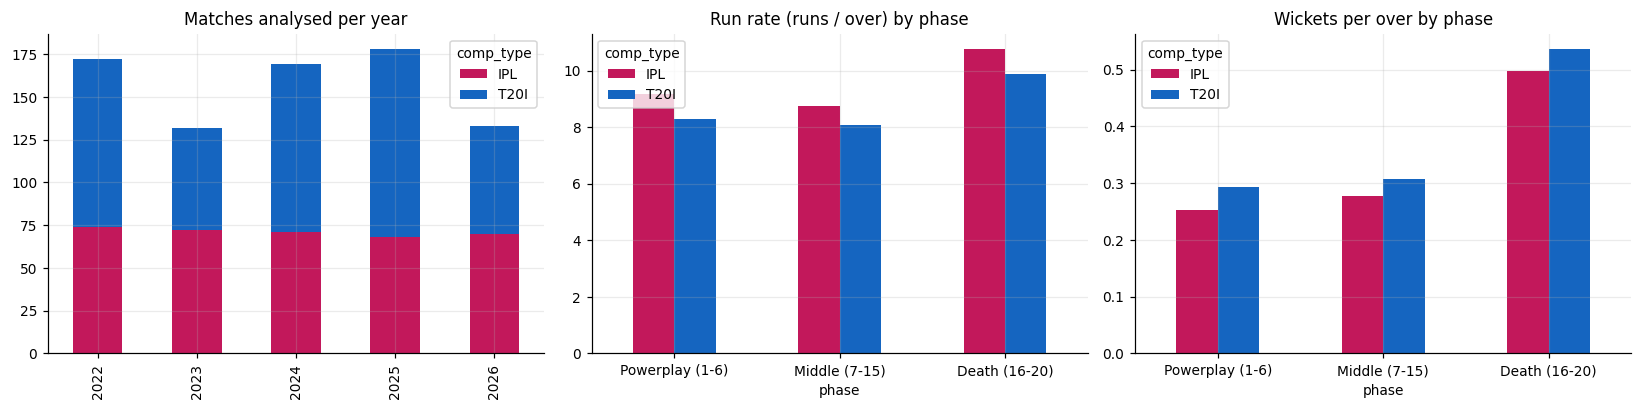

,matches,avg_inn1,avg_inn2,chasing_win_pct
comp_type,,,,
IPL,355,186.282,171.856,52.113
T20I,429,171.207,150.876,48.485


Toss decision -> chose to field: 0.736 | toss winner also match winner: 0.513


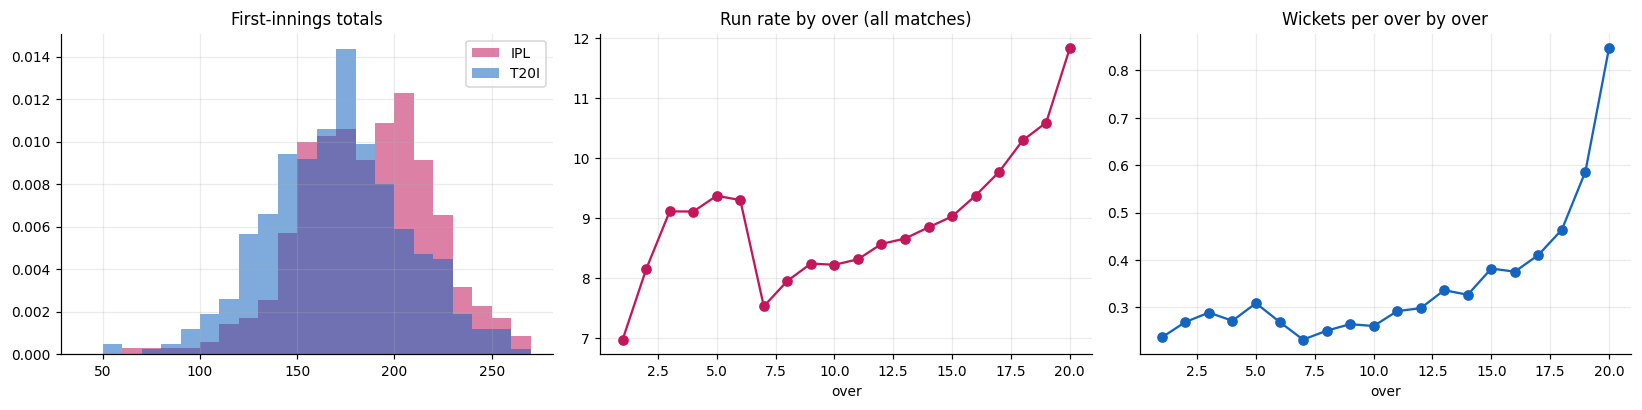

player-match appearances in analysed matches (playing_eleven): 17836 | impact-player appearances: 539
batting-order distribution of ball-by-ball striker (share of deliveries faced):
batting_order     1     2     3     4     5     6     7     8
share         0.170 0.173 0.155 0.149 0.120 0.090 0.065 0.079


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cov = mm.groupby([mm.match_date.dt.year, 'comp_type']).size().unstack(fill_value=0); cov.plot.bar(stacked=True, ax=ax[0], color=['#c2185b', '#1565c0']); ax[0].set_title('Matches analysed per year'); ax[0].set_xlabel('')
ph = d.groupby(['comp_type', 'phase'], observed=True).agg(balls=('legal_i', 'sum'), runs=('total_runs', 'sum'), wk=('wk_i', 'sum')).reset_index()
ph['rpo'] = ph.runs / ph.balls * 6; ph['wk_per_over'] = ph.wk / ph.balls * 6
pv = ph.pivot(index='phase', columns='comp_type', values='rpo'); pv.plot.bar(ax=ax[1], color=['#c2185b', '#1565c0'], rot=0); ax[1].set_title('Run rate (runs / over) by phase')
pv = ph.pivot(index='phase', columns='comp_type', values='wk_per_over'); pv.plot.bar(ax=ax[2], color=['#c2185b', '#1565c0'], rot=0); ax[2].set_title('Wickets per over by phase')
plt.tight_layout(); plt.show()

inn = d.groupby(['match_id', 'comp_type', 'innings']).agg(runs=('total_runs', 'sum'), wk=('wk_i', 'sum')).reset_index()
res = inn.pivot_table(index=['match_id', 'comp_type'], columns='innings', values='runs').reset_index().rename(columns={1: 'inn1', 2: 'inn2'})
res = res.merge(mm[['match_id', 'win_team_id', 'toss_win_team_id', 'toss_opted']], on='match_id')
first_bat = d[d.innings == 1].groupby('match_id').batting_team_id.first()
res['chase_win'] = res.match_id.map(lambda x: mm.set_index('match_id').win_team_id[x] != first_bat[x]).astype(int)
tab = res.groupby('comp_type').agg(matches=('match_id', 'size'), avg_inn1=('inn1', 'mean'), avg_inn2=('inn2', 'mean'), chasing_win_pct=('chase_win', 'mean'))
tab['chasing_win_pct'] *= 100
display(tab)
print('Toss decision -> chose to field:', (mm.toss_opted == 'Fielding').mean().round(3), '| toss winner also match winner:', (mm.toss_win_team_id == mm.win_team_id).mean().round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for ct, c in (('IPL', '#c2185b'), ('T20I', '#1565c0')):
    ax[0].hist(res[res.comp_type == ct].inn1, bins=np.arange(40, 280, 10), alpha=.55, label=ct, color=c, density=True)
ax[0].set_title('First-innings totals'); ax[0].legend()
ov = d.groupby('overid').agg(r=('total_runs', 'sum'), n=('legal_i', 'sum')); ax[1].plot(ov.index, ov.r / ov.n * 6, marker='o', color='#c2185b'); ax[1].set_title('Run rate by over (all matches)'); ax[1].set_xlabel('over')
wk = d.groupby(['overid']).wk_i.sum() / d.groupby('overid').legal_i.sum() * 6; ax[2].plot(wk.index, wk, marker='o', color='#1565c0'); ax[2].set_title('Wickets per over by over'); ax[2].set_xlabel('over')
plt.tight_layout(); plt.show()

# how are the supporting files used? players per team type and playing-XI roles
xi_a = xi[xi.match_id.isin(mm.match_id) & (xi.is_played == True)]
print('player-match appearances in analysed matches (playing_eleven):', len(xi_a), '| impact-player appearances:', int((xi_a.is_impact == 1).sum()))
print('batting-order distribution of ball-by-ball striker (share of deliveries faced):')
print((d[d.bat_faced].batting_order.clip(upper=8).value_counts(normalize=True).sort_index().rename('share')).to_frame().T.to_string())

# 6. Defining pressure

## 6.1 Why a win-probability model?
The problem statement lists required run rate, wickets in hand, balls remaining, stage of the innings and closeness of the contest. These factors interact (a required rate of 12 is routine with 9 wickets in hand and 4 overs left, and desperate with 4 wickets in hand and 12 balls left), so any hand-built score needs arbitrary weights. A win-probability model learns the interaction directly from 187k deliveries:

`WP(state) = P(batting team wins | innings, balls left, wickets lost, runs, target, required rate, team-strength gap, venue par, competition)`

* Gradient-boosted trees, deliberately **smooth** (small trees, large leaves, strong L2) because a jittery WP model manufactures fake pressure.
* **Out-of-fold predictions**: five folds grouped by match, so a delivery is always scored by a model that never saw its match.

,AUC_model,Brier_model,LogLoss_model,Brier_baseline,LogLoss_baseline
innings,,,,,
1st innings (baseline = coin flip),0.697,0.221,0.633,0.250,0.693
2nd innings (baseline = logistic regression),0.897,0.131,0.404,0.131,0.405


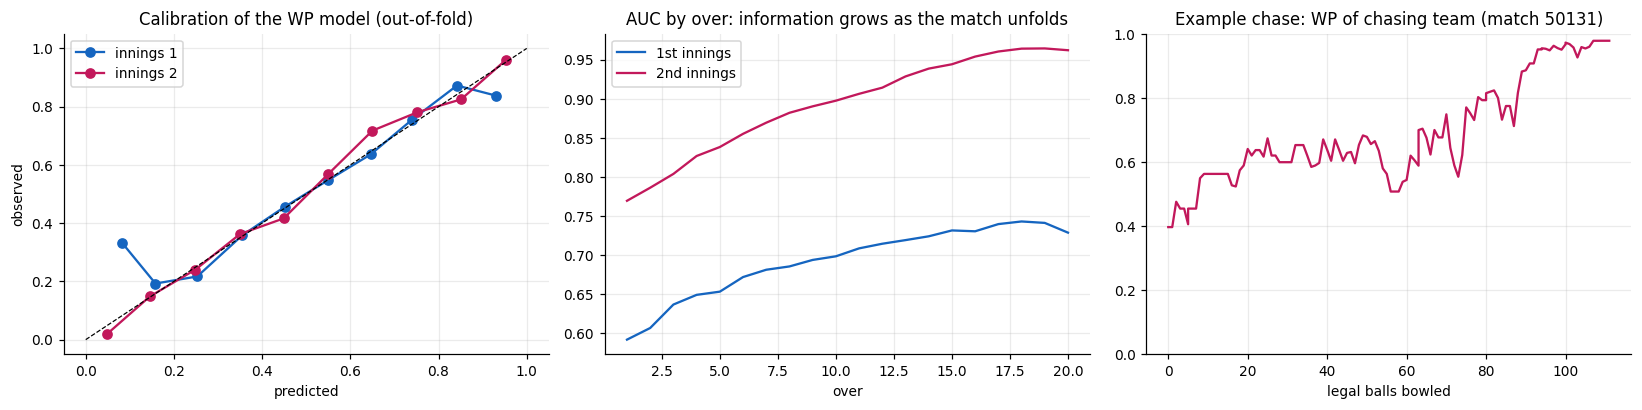

In [27]:
WPF = ['innings', 'balls_left', 'wkts', 'runs_so_far', 'rrr', 'runs_needed', 'elo_diff', 'is_ipl', 'venue_par']
gkf = GroupKFold(CV_FOLDS); groups = d.match_id.values
y = d.bat_win.values
oof = np.zeros(len(d))
for tr, te in gkf.split(d, y, groups):
    m_ = HGBC(max_iter=150, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=1500, l2_regularization=5.0, random_state=SEED)
    m_.fit(d.iloc[tr][WPF], y[tr]); oof[te] = m_.predict_proba(d.iloc[te][WPF])[:, 1]
d['wp'] = oof

# baseline for comparison
rows = []
for i in (1, 2):
    k = (d.innings == i).values
    base = np.full(k.sum(), 0.5)
    if i == 2:
        Xl = np.c_[d.rrr[k].clip(upper=36), d.wkts[k], d.balls_left[k], d.runs_needed[k], d.elo_diff[k] / 100]
        lo = np.zeros(k.sum())
        for tr, te in GroupKFold(CV_FOLDS).split(Xl, y[k], groups[k]):
            lr = LogisticRegression(max_iter=500).fit(Xl[tr], y[k][tr]); lo[te] = lr.predict_proba(Xl[te])[:, 1]
        base = lo
    rows.append(dict(innings=i, AUC_model=roc_auc_score(y[k], oof[k]), Brier_model=brier_score_loss(y[k], oof[k]), LogLoss_model=log_loss(y[k], oof[k]),
                     Brier_baseline=brier_score_loss(y[k], base), LogLoss_baseline=log_loss(y[k], base)))
display(pd.DataFrame(rows).set_index('innings').rename(index={1: '1st innings (baseline = coin flip)', 2: '2nd innings (baseline = logistic regression)'}))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for i, c in ((1, '#1565c0'), (2, '#c2185b')):
    k = (d.innings == i).values; bins = np.clip((oof[k] * 10).astype(int), 0, 9)
    cal = pd.DataFrame({'p': oof[k], 'y': y[k], 'b': bins}).groupby('b').mean(); ax[0].plot(cal.p, cal.y, marker='o', color=c, label=f'innings {i}')
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_title('Calibration of the WP model (out-of-fold)'); ax[0].set_xlabel('predicted'); ax[0].set_ylabel('observed'); ax[0].legend()
auc_over = [(o, roc_auc_score(y[(d.innings == 2) & (d.overid == o)], oof[(d.innings == 2) & (d.overid == o)])) for o in range(1, 21)]
auc1 = [(o, roc_auc_score(y[(d.innings == 1) & (d.overid == o)], oof[(d.innings == 1) & (d.overid == o)])) for o in range(1, 21)]
ax[1].plot(*zip(*auc1), color='#1565c0', label='1st innings'); ax[1].plot(*zip(*auc_over), color='#c2185b', label='2nd innings'); ax[1].set_title('AUC by over: information grows as the match unfolds'); ax[1].set_xlabel('over'); ax[1].legend()
ex = d[(d.match_id == d[(d.innings == 2)].groupby('match_id').size().sort_values().index[len(mm)//2]) & (d.innings == 2)]
ax[2].plot(ex.balls_bowled, ex.wp, color='#c2185b'); ax[2].set_title(f'Example chase: WP of chasing team (match {ex.match_id.iloc[0]})'); ax[2].set_xlabel('legal balls bowled'); ax[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 6.2 From win probability to a Pressure Index (leverage)

* **Win-probability added (WPA)** of a delivery = WP after − WP before (batting-team view). The hand-over between innings is not a ball outcome and is left out.
* **Leverage** of a state = the *expected absolute swing* in WP that the next delivery produces, `E[|ΔWP| | state]`. We estimate it with a second smooth model (Poisson loss, out-of-fold) so that it is a property of the **situation**, not of the lucky outcome that happened.
* **Pressure Index (PI)** = leverage divided by its average, so PI = 1 is a typical ball and PI = 3 is a ball that matters three times as much. Both teams feel it: a batter needing 12 off 6 and a bowler defending them are in the same state.
* **High pressure (HP)** = PI in the **top quartile within its innings**. Ranking within the innings keeps first-innings pressure (a total is being set, outcome still fuzzy) comparable to chase pressure (a target exists) instead of letting the chase dominate every list. A global threshold is used as a robustness variant in section 10.

In [28]:
g = d.groupby(['match_id', 'innings'], sort=False)
d['wp_next'] = g.wp.shift(-1)
last = d.wp_next.isna()
d.loc[last & (d.innings == 2), 'wp_next'] = d.loc[last & (d.innings == 2), 'bat_win'].astype(float)
d['dwp'] = d.wp_next - d.wp
d['abs_dwp'] = d.dwp.abs(); ok = d.dwp.notna().values

LIF = WPF + ['wp']
y_li = d.abs_dwp.values; oofli = np.zeros(len(d))
for tr, te in gkf.split(d, y_li, groups):
    tr = tr[ok[tr]]
    r_ = HGBR(loss='poisson', max_iter=150, learning_rate=0.05, max_leaf_nodes=12, min_samples_leaf=800, l2_regularization=3.0, random_state=SEED)
    r_.fit(d.iloc[tr][LIF], y_li[tr]); oofli[te] = r_.predict(d.iloc[te][LIF])
d['pi_global'] = oofli / oofli.mean()                                  # pressure index
d['pi_pct_in'] = d.groupby('innings').pi_global.rank(pct=True)         # percentile within innings
d['hp'] = d.pi_pct_in >= HP_PCT                                        # HIGH-PRESSURE flag
d['pi_n'] = d.pi_global / d.groupby('innings').pi_global.transform('mean')   # normalised within innings
d['w'] = d.pi_n.clip(upper=LI_CAP)                                     # weight used inside HP aggregation

print('corr(PI, realised |dWP|) =', round(np.corrcoef(d.pi_global[ok], d.abs_dwp[ok])[0, 1], 3))
print(d.pi_global.describe(percentiles=[.25, .5, .75, .9, .99]).round(2).to_dict())
print('HP share of deliveries by innings x phase:')
display(d.groupby(['innings', 'phase'], observed=True).hp.mean().unstack().mul(100).round(1))

corr(PI, realised |dWP|) = 0.515
{'count': 187142.0, 'mean': 1.0, 'std': 1.35, 'min': 0.08, '25%': 0.4, '50%': 0.65, '75%': 1.16, '90%': 1.96, '99%': 5.96, 'max': 44.3}
HP share of deliveries by innings x phase:


phase,Powerplay (1-6),Middle (7-15),Death (16-20)
innings,,,
1,5.200,22.200,53.900
2,15.300,29.000,31.500


## 6.3 What does pressure look like? (and does it separate pressure from ordinary play?)

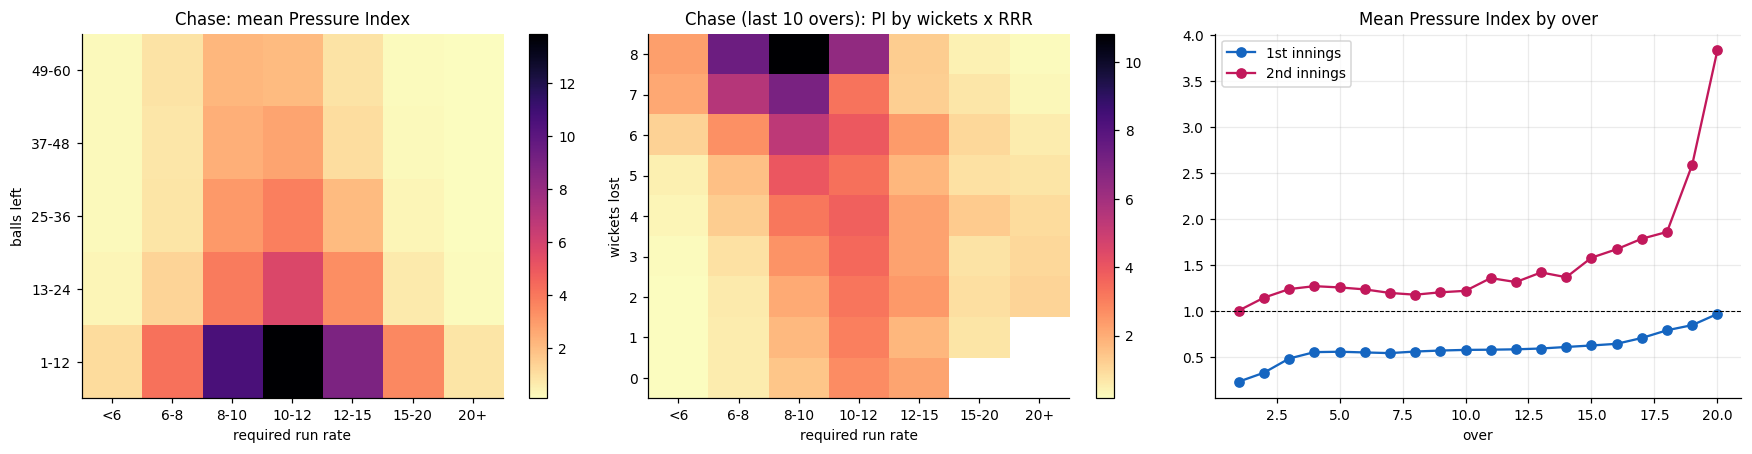

deliveries  mean_PI  avg |dWP| (pp)  runs_per_over  dot_pct  boundary_pct  wicket_pct
innings hp_lbl                                                                                              
1       High pressure       24389    0.962           1.191          8.989   28.960        17.984       6.560
        Ordinary            73157    0.471           0.510          8.451   34.384        18.119       4.854
2       High pressure       22399    3.343           3.963          8.735   30.698        18.144       5.947
        Ordinary            67197    0.808           0.927          8.315   35.865        17.961       5.305

Share of all win-probability movement that happens on the 25% HP deliveries: {1: 43.3, 2: 58.8} (chance level = 25)


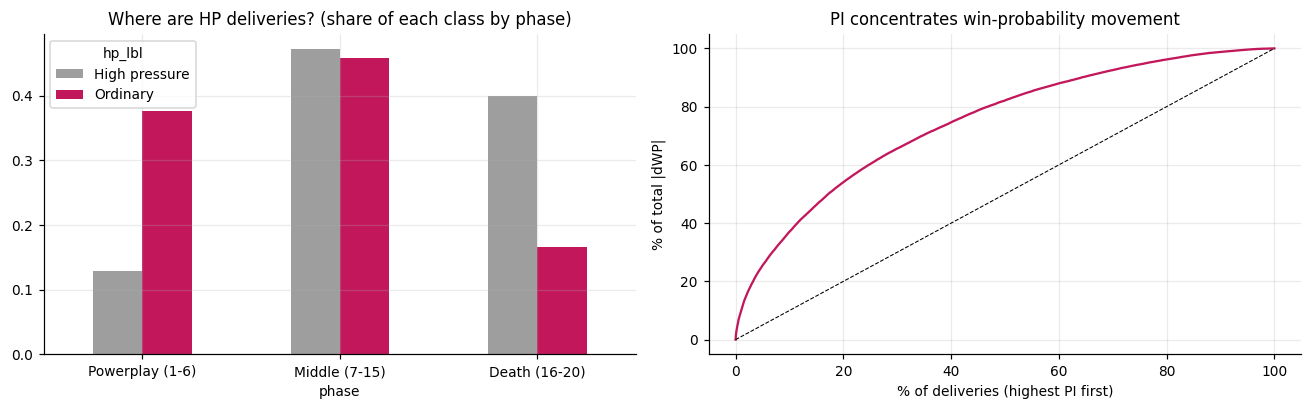

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
c2 = d[(d.innings == 2) & (d.balls_left <= 60)].copy()
c2['rrr_b'] = pd.cut(c2.rrr, [0, 6, 8, 10, 12, 15, 20, 40], labels=['<6', '6-8', '8-10', '10-12', '12-15', '15-20', '20+'])
c2['bl_b'] = pd.cut(c2.balls_left, [0, 12, 24, 36, 48, 60], labels=['1-12', '13-24', '25-36', '37-48', '49-60'])
hm = c2.pivot_table(index='bl_b', columns='rrr_b', values='pi_global', aggfunc='mean', observed=True)
im = ax[0].imshow(hm.values, aspect='auto', cmap='magma_r', origin='lower'); ax[0].set_xticks(range(hm.shape[1])); ax[0].set_xticklabels(hm.columns); ax[0].set_yticks(range(hm.shape[0])); ax[0].set_yticklabels(hm.index)
ax[0].set_xlabel('required run rate'); ax[0].set_ylabel('balls left'); ax[0].set_title('Chase: mean Pressure Index'); ax[0].grid(False); plt.colorbar(im, ax=ax[0])
c2['wk_b'] = c2.wkts.clip(upper=8)
hm2 = c2.pivot_table(index='wk_b', columns='rrr_b', values='pi_global', aggfunc='mean', observed=True)
im = ax[1].imshow(hm2.values, aspect='auto', cmap='magma_r', origin='lower'); ax[1].set_xticks(range(hm2.shape[1])); ax[1].set_xticklabels(hm2.columns); ax[1].set_yticks(range(hm2.shape[0])); ax[1].set_yticklabels(hm2.index)
ax[1].set_xlabel('required run rate'); ax[1].set_ylabel('wickets lost'); ax[1].set_title('Chase (last 10 overs): PI by wickets x RRR'); ax[1].grid(False); plt.colorbar(im, ax=ax[1])
pr = d.groupby(['innings', 'overid']).pi_global.mean().unstack(0); ax[2].plot(pr.index, pr[1], label='1st innings', color='#1565c0', marker='o'); ax[2].plot(pr.index, pr[2], label='2nd innings', color='#c2185b', marker='o')
ax[2].axhline(1, color='k', ls='--', lw=.7); ax[2].set_xlabel('over'); ax[2].set_title('Mean Pressure Index by over'); ax[2].legend()
plt.tight_layout(); plt.show()

# pressure vs ordinary: outcomes
d['hp_lbl'] = np.where(d.hp, 'High pressure', 'Ordinary')
cmp_ = d.groupby(['innings', 'hp_lbl']).agg(deliveries=('w', 'size'), runs_per_ball=('total_runs', 'mean'), six=('is_six', 'mean'), four=('is_four', 'mean'),
                                            dot_pct=('total_runs', lambda s: (s == 0).mean()), wicket_pct=('wk_i', 'mean'), mean_abs_dWP=('abs_dwp', 'mean'), mean_PI=('pi_global', 'mean'))
cmp_['boundary_pct'] = (cmp_.four + cmp_.six) * 100; cmp_['dot_pct'] *= 100; cmp_['wicket_pct'] *= 100; cmp_['mean_abs_dWP'] *= 100
cmp_['runs_per_over'] = cmp_.runs_per_ball * 6
display(cmp_[['deliveries', 'mean_PI', 'mean_abs_dWP', 'runs_per_over', 'dot_pct', 'boundary_pct', 'wicket_pct']].rename(columns={'mean_abs_dWP': 'avg |dWP| (pp)'}))
tot_swing = d.groupby('innings').apply(lambda x: x.loc[x.hp, 'abs_dwp'].sum() / x.abs_dwp.sum())
print('Share of all win-probability movement that happens on the 25% HP deliveries:', tot_swing.mul(100).round(1).to_dict(), '(chance level = 25)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pp = d.groupby(['hp_lbl', 'phase'], observed=True).size().unstack(0); (pp / pp.sum()).plot.bar(ax=ax[0], color=['#9e9e9e', '#c2185b'], rot=0); ax[0].set_title('Where are HP deliveries? (share of each class by phase)')
srt = d.sort_values('pi_global', ascending=False); cum = srt.abs_dwp.fillna(0).cumsum() / srt.abs_dwp.fillna(0).sum()
ax[1].plot(np.arange(len(srt)) / len(srt) * 100, cum * 100, color='#c2185b'); ax[1].plot([0, 100], [0, 100], 'k--', lw=.7); ax[1].set_xlabel('% of deliveries (highest PI first)'); ax[1].set_ylabel('% of total |dWP|'); ax[1].set_title('PI concentrates win-probability movement')
plt.tight_layout(); plt.show()

# 7. Performance measurement: value above what the situation normally yields

Raw strike rate or economy under pressure is misleading: scoring 8 off a ball at 19.4 in a chase is not the same as scoring 8 off a ball in the middle overs, and facing a part-timer is not the same as facing the opposition's best. So every delivery is compared with the **expected outcome for that situation**, from baseline models that know the situation but **not the player**:

| baseline model | target | context features |
|---|---|---|
| expected bat runs | runs off the bat (non-wides) | innings, balls left, wickets, runs, required rate, runs needed, venue par, IPL flag, **batting position** (role), pace/spin, **bowling-side Elo** |
| expected dismissal prob. | striker out | same |
| expected runs conceded | runs charged to bowler | same, with **batting position of the striker** and **batting-side Elo** |
| expected bowler wicket prob. | bowler-credited wicket | same |
| value of a wicket in runs (λ) | run expectancy lost when a wicket falls (first innings, monotone in balls & wickets) | balls left, wickets, venue par, IPL flag |

All models are out-of-fold. Opposition strength enters as a feature, so scoring freely against weak attacks is *expected* and earns nothing extra.

**Per-delivery value**
* Batter: `BV = (runs − E[runs]) − λ · (out − E[out])`  (runs above expected, with wickets priced in runs)
* Bowler: `BWV = −(runs conceded − E[conceded]) + λ · (wicket − E[wicket])`
* **WPA** (from section 6) is kept as a second, stakes-aware measure: it is the same outcome seen through the win-probability lens, so a boundary at PI = 4 is worth far more than one at PI = 0.3.

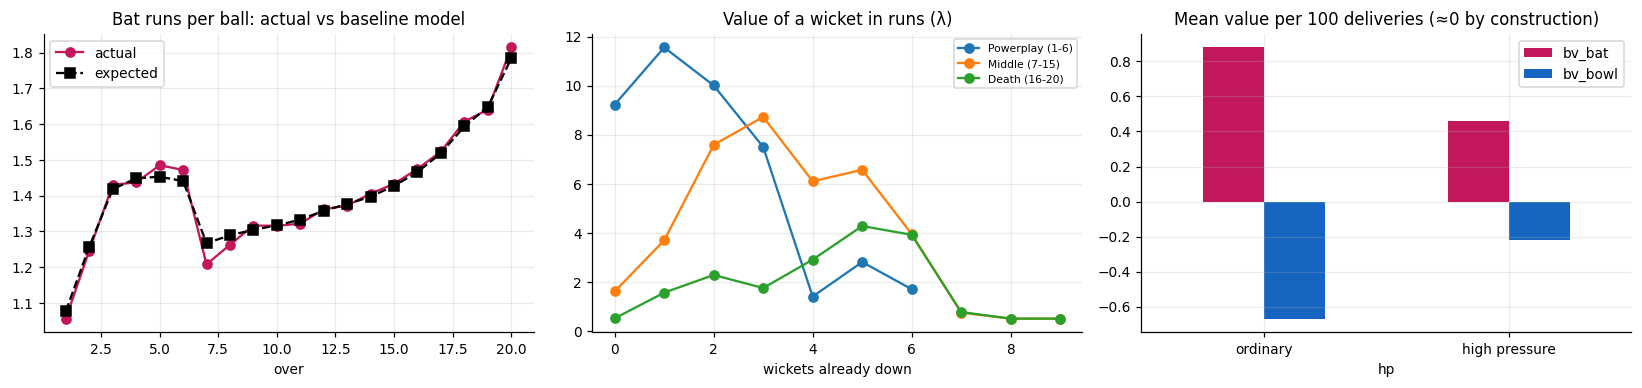

,actual_runs,exp_runs,actual_out,exp_out
hp,,,,
False,1.377,1.376,0.051,0.052
True,1.464,1.465,0.063,0.062


In [30]:
d['bo']   = d.batting_order.clip(upper=7)
d['spin'] = (d.pace_or_spin == 'Spin').astype(int)
BF  = ['innings', 'balls_left', 'wkts', 'runs_so_far', 'rrr', 'runs_needed', 'venue_par', 'is_ipl', 'bo', 'spin', 'bowl_elo']
BWF = ['innings', 'balls_left', 'wkts', 'runs_so_far', 'rrr', 'runs_needed', 'venue_par', 'is_ipl', 'bo', 'spin', 'bat_elo']
reg = lambda: HGBR(max_iter=150, learning_rate=0.05, max_leaf_nodes=16, min_samples_leaf=300, l2_regularization=2.0, random_state=SEED)
clf = lambda: HGBC(max_iter=150, learning_rate=0.05, max_leaf_nodes=12, min_samples_leaf=400, l2_regularization=2.0, random_state=SEED)

def oof_fit(fn, F, target, mask):
    out = np.full(len(d), np.nan)
    for tr, te in gkf.split(d, groups=groups):
        trm = tr[mask[tr]]; mdl = fn(); mdl.fit(d.iloc[trm][F], target[trm])
        out[te] = mdl.predict_proba(d.iloc[te][F])[:, 1] if hasattr(mdl, 'predict_proba') else mdl.predict(d.iloc[te][F])
    return out

allm = np.ones(len(d), bool); bf = d.bat_faced.values
d['mu_runs'] = oof_fit(reg, BF,  d.runs.values.astype(float), bf)
d['mu_bout'] = oof_fit(clf, BF,  d.striker_out.values.astype(int), bf)
d['mu_conc'] = oof_fit(reg, BWF, d.bowler_runs.values.astype(float), allm)
d['mu_bwk']  = oof_fit(clf, BWF, d.bowler_wkt.values.astype(int), allm)

# value of a wicket in runs (lambda): run-expectancy difference between w and w+1 wickets down, one ball later (1st innings, monotone)
d['rem'] = d.inn1_total.where(d.innings == 1) - d.runs_so_far
REF = ['balls_left', 'wkts', 'venue_par', 'is_ipl']; lam = np.zeros(len(d)); m1 = (d.innings == 1).values
for tr, te in gkf.split(d, groups=groups):
    trm = tr[m1[tr]]
    mdl = HGBR(max_iter=150, learning_rate=0.05, max_leaf_nodes=16, min_samples_leaf=300, l2_regularization=2.0, monotonic_cst=[1, -1, 0, 0], random_state=SEED).fit(d.iloc[trm][REF], d.rem.values[trm])
    x = d.iloc[te][REF].copy(); x['balls_left'] = (x.balls_left - 1).clip(lower=0); x2 = x.copy(); x2['wkts'] = (x2.wkts + 1).clip(upper=10)
    lam[te] = mdl.predict(x) - mdl.predict(x2)
d['lam'] = np.clip(lam, 0.5, None)

d['r_bat']  = np.where(d.bat_faced, d.runs - d.mu_runs, 0.0)                               # runs part
d['k_bat']  = np.where(d.bat_faced, -d.lam * (d.striker_out.astype(int) - d.mu_bout), 0.0) # wicket part (runs)
d['r_bowl'] = -(d.bowler_runs - d.mu_conc); d['k_bowl'] = d.lam * (d.bowler_wkt.astype(int) - d.mu_bwk)
d['bv_bat']   = np.where(d.bat_faced, (d.runs - d.mu_runs) - d.lam * (d.striker_out.astype(int) - d.mu_bout), 0.0)
d['bv_bowl']  = -(d.bowler_runs - d.mu_conc) + d.lam * (d.bowler_wkt.astype(int) - d.mu_bwk)
d['wpa_bat']  = np.where(d.bat_faced, d.dwp.fillna(0), 0.0)
d['wpa_bowl'] = -d.dwp.fillna(0)

# --- sanity: baselines are calibrated by over and by pressure class
chk = d[d.bat_faced].groupby('overid').agg(actual=('runs', 'mean'), expected=('mu_runs', 'mean'))
chk2 = d[d.bat_faced].groupby('hp').agg(actual_runs=('runs', 'mean'), exp_runs=('mu_runs', 'mean'), actual_out=('striker_out', 'mean'), exp_out=('mu_bout', 'mean'))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(chk.index, chk.actual, 'o-', label='actual', color='#c2185b'); ax[0].plot(chk.index, chk.expected, 's--', label='expected', color='k'); ax[0].set_title('Bat runs per ball: actual vs baseline model'); ax[0].set_xlabel('over'); ax[0].legend()
lt = d.groupby(['wkts', 'phase'], observed=True).lam.mean().unstack(); lt.loc[:9].plot(ax=ax[1], marker='o'); ax[1].set_title('Value of a wicket in runs (λ)'); ax[1].set_xlabel('wickets already down'); ax[1].legend(fontsize=7)
d.groupby('hp')[['bv_bat', 'bv_bowl']].mean().mul(100).plot.bar(ax=ax[2], rot=0, color=['#c2185b', '#1565c0']); ax[2].set_title('Mean value per 100 deliveries (≈0 by construction)'); ax[2].set_xticklabels(['ordinary', 'high pressure'])
plt.tight_layout(); plt.show(); display(chk2)

# 8. Player-level metrics: a hierarchical (empirical-Bayes) model

Pressure samples are small (a regular has 200–600 high-pressure deliveries) and cricket outcomes are noisy, so raw pressure numbers mostly measure luck. Our diagnostics showed that shrinking a single combined number is not enough, so the model is built in three layers.

**Layer 1: two parts per delivery.** Value = *runs part* (runs above expected for batters, runs saved for bowlers) + *wicket part* (λ-priced dismissals / wickets above expected). The parts have very different noise-to-signal ratios, so each is modelled separately and then added.

**Layer 2: ability = usual level + pressure uplift.** For player *i* and each part:
* ordinary deliveries: `m_lp ~ N(μᵢ, v_lp)`
* high-pressure deliveries (PI-weighted): `m_hp ~ N(μᵢ + δᵢ, v_hp)`
* `μᵢ ~ N(μ̄, τ²_μ)` (spread of true usual ability), `δᵢ ~ N(δ̄, τ²_δ)` (spread of true pressure uplift).

`v` are **cluster-robust** sampling variances (deliveries inside the same innings are correlated, so the unit of independent evidence is the *appearance*, not the ball). Hyper-parameters (μ̄, δ̄, τ²_μ, τ²_δ) are fitted by maximum marginal likelihood across players, and each player's posterior is computed in closed form. The result borrows strength from the (3-4× larger) ordinary sample when estimating pressure ability, and shrinks a player's *extra* pressure effect only as far as the data justify.

**Outputs per player**
| component | meaning |
|---|---|
| **Level** `θ = μ + δ` | posterior pressure ability, runs above expected (batter) / runs saved (bowler) per delivery, wickets priced in |
| **Resilience** `δ` | posterior pressure uplift versus the player's own usual level |
| **Consistency** | Beta-smoothed share of *pressure appearances* (innings/spell with ≥ 4 HP deliveries) with positive value |
| WPA (descriptive) | win probability added per 100 HP deliveries; shown as evidence, **not** rated, because its persistence test is ~0 (section 10) |

**Eligibility**: ≥ 100 HP deliveries and ≥ 15 pressure appearances. IPL and T20I are pooled; competition, venue and opposition strength are already in the baselines.

**Fitted hyper-parameters** (runs per delivery; r = runs part, k = wicket part)

batting       bowling       
                                      r     k       r      k
usual mean (μ̄)                  -0.013 0.023  -0.001 -0.027
pressure shift (δ̄)              -0.007 0.001   0.005 -0.013
sd of true usual ability (τμ)     0.112 0.049   0.089  0.049
sd of true pressure uplift (τδ)   0.104 0.046   0.063  0.084

batters: 815 with any ball, 82 eligible | bowlers: 587 with any ball, 97 eligible


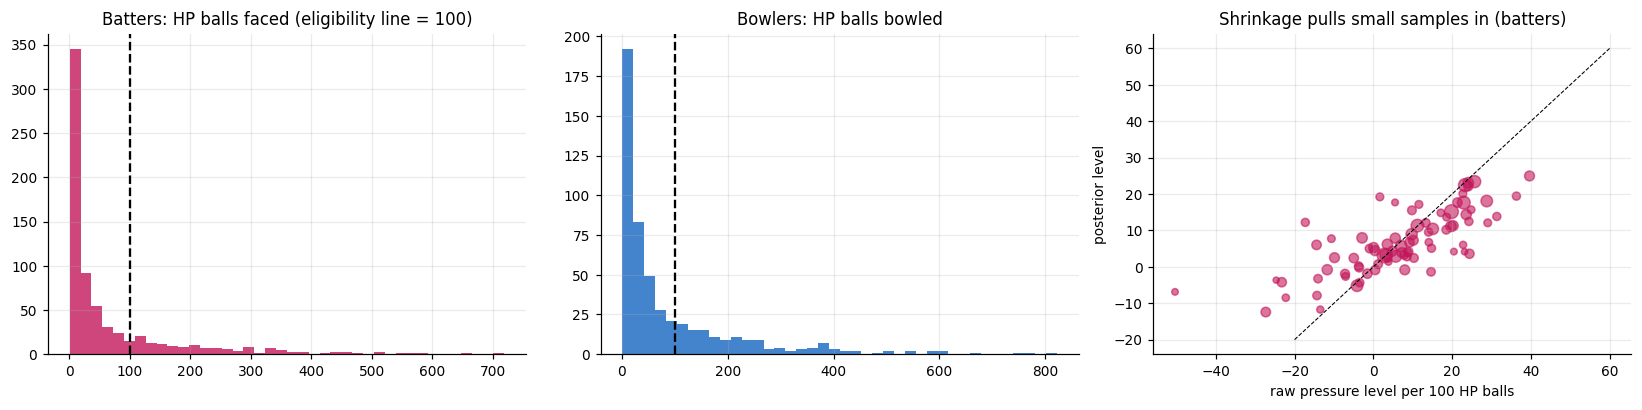

In [31]:
def agg_table(df, pid, rc, kc, wpac, hpcol='hp', wcol='w'):
    """one row per (player, match, innings) = one independent 'cluster'; sums split into high-pressure (PI-weighted) and ordinary parts"""
    x = df[[pid, 'match_id', 'innings']].copy(); w = df[wcol].values; h = df[hpcol].values.astype(float); l = 1 - h; r = df[rc].values; k = df[kc].values
    x['n_hp'] = h; x['sw_hp'] = w * h; x['xr_hp'] = w * h * r; x['xk_hp'] = w * h * k; x['bv_hp_u'] = h * (r + k); x['wpa_hp'] = h * df[wpac].values
    x['n_lp'] = l; x['xr_lp'] = l * r; x['xk_lp'] = l * k
    P = x.groupby([pid, 'match_id', 'innings'], sort=False).sum().reset_index().rename(columns={pid: 'pid'})
    P['A_hp'] = (P.n_hp > 0).astype(float); P['A_lp'] = (P.n_lp > 0).astype(float); P['sw2_hp'] = P.sw_hp ** 2; P['n2_lp'] = P.n_lp ** 2
    for c in ('r', 'k'):
        P[f'x{c}2_hp'] = P[f'x{c}_hp'] ** 2; P[f'x{c}s_hp'] = P[f'x{c}_hp'] * P.sw_hp; P[f'x{c}2_lp'] = P[f'x{c}_lp'] ** 2; P[f'x{c}s_lp'] = P[f'x{c}_lp'] * P.n_lp
    P['ap'] = (P.n_hp >= MIN_PA_BALLS).astype(float); P['ap_win'] = ((P.n_hp >= MIN_PA_BALLS) & (P.bv_hp_u > 0)).astype(float)
    return P
SUMC = ['n_hp', 'sw_hp', 'xr_hp', 'xk_hp', 'bv_hp_u', 'wpa_hp', 'n_lp', 'xr_lp', 'xk_lp', 'A_hp', 'A_lp', 'sw2_hp', 'n2_lp', 'xr2_hp', 'xrs_hp', 'xk2_hp', 'xks_hp', 'xr2_lp', 'xrs_lp', 'xk2_lp', 'xks_lp', 'ap', 'ap_win']
def sums(P, match_w=None):
    """player totals; match_w (match -> multiplicity) enables bootstrap resamples and split-halves"""
    Q = P if match_w is None else P.assign(**{c: P[c] * P.match_id.map(match_w).fillna(0).values for c in SUMC})
    return Q.groupby('pid')[SUMC].sum()

def comp_stats(S, c):
    """raw mean and cluster-robust variance of the mean for part c, for HP and ordinary deliveries"""
    out = {}
    for cls, sw, sw2, A in (('hp', 'sw_hp', 'sw2_hp', 'A_hp'), ('lp', 'n_lp', 'n2_lp', 'A_lp')):
        s = S[sw].replace(0, np.nan); m = S[f'x{c}_{cls}'] / s
        ss = (S[f'x{c}2_{cls}'] - 2 * m * S[f'x{c}s_{cls}'] + m ** 2 * S[sw2]).clip(lower=0); a = S[A]
        out[cls] = (m, ss / s ** 2 * (a / (a - 1).replace(0, np.nan)), a)
    return out

def fit_hyper(m_h, v_h, m_l, v_l, ok):
    """maximum marginal likelihood for (mu_bar, delta_bar, tau_mu^2, tau_delta^2)"""
    mh, vh, ml, vl = [np.asarray(z[ok], float) for z in (m_h, v_h, m_l, v_l)]
    def nll(p):
        mu, dl, la, lb = p; a, b = np.exp(la), np.exp(lb); s11 = a + b + vh; s22 = a + vl; det = s11 * s22 - a ** 2; e1 = mh - (mu + dl); e2 = ml - mu
        return 0.5 * np.sum(np.log(det) + (s22 * e1 ** 2 - 2 * a * e1 * e2 + s11 * e2 ** 2) / det)
    best = None
    for init in ([0, 0, np.log(1e-3), np.log(1e-3)], [0, 0, np.log(1e-2), np.log(1e-2)], [0, 0, np.log(1e-2), np.log(1e-4)]):
        r = minimize(nll, init, method='Nelder-Mead', options=dict(maxiter=4000, xatol=1e-7, fatol=1e-9))
        if best is None or r.fun < best.fun: best = r
    return dict(mu=best.x[0], delta=best.x[1], tau_mu2=np.exp(best.x[2]), tau_d2=np.exp(best.x[3]))

def posterior(m_h, v_h, m_l, v_l, hp):
    """closed-form posterior mean of (mu_i, delta_i) and sd of theta_i = mu_i + delta_i"""
    mu0, d0, a, b = hp['mu'], hp['delta'], hp['tau_mu2'], hp['tau_d2']; BIG = 1e6
    m_h = m_h.fillna(mu0 + d0); v_h = v_h.fillna(BIG).clip(lower=1e-9); m_l = m_l.fillna(mu0); v_l = v_l.fillna(BIG).clip(lower=1e-9); ih, il = 1 / v_h, 1 / v_l
    P11 = 1 / a + ih + il; P12 = ih; P22 = 1 / b + ih; det = P11 * P22 - P12 ** 2
    r1 = mu0 / a + m_h * ih + m_l * il; r2 = d0 / b + m_h * ih
    return (P22 * r1 - P12 * r2) / det, (-P12 * r1 + P11 * r2) / det, np.sqrt((P22 + P11 - 2 * P12) / det)

def fit_all(S):
    hps = {}
    for c in ('r', 'k'):
        (mh, vh, ah), (ml, vl, al) = comp_stats(S, c)['hp'], comp_stats(S, c)['lp']
        ok = ((ah >= 5) & (al >= 5) & (S.n_hp >= 20) & (S.n_lp >= 50)).values; hps[c] = fit_hyper(mh, vh, ml, vl, ok)
    pa = S[S.ap > 0]; hps['rho'] = pa.ap_win.sum() / pa.ap.sum(); return hps

def metrics(S, hps):
    t = S[['n_hp', 'n_lp', 'ap', 'ap_win', 'wpa_hp']].copy(); mu = 0; dl = 0; var = 0
    for c in ('r', 'k'):
        st = comp_stats(S, c); mu_p, d_p, sd = posterior(*st['hp'][:2], *st['lp'][:2], hps[c]); t[f'mu_{c}'] = mu_p; t[f'dl_{c}'] = d_p; mu = mu + mu_p; dl = dl + d_p; var = var + sd ** 2
        t[f'raw_hp_{c}'] = st['hp'][0]
    t['usual'] = mu; t['resilience'] = dl; t['level'] = mu + dl; t['level_sd'] = np.sqrt(var)
    t['raw_level'] = t.raw_hp_r + t.raw_hp_k
    t['consistency'] = (t.ap_win + BETA_K * hps['rho']) / (t.ap + BETA_K); t['wpa_100'] = t.wpa_hp / t.n_hp.replace(0, np.nan) * 100 * 100   # pp per 100 deliveries
    return t

def rate(t, elig, w=WEIGHTS):
    e = t[elig].copy(); z = lambda s: (s - s.mean()) / s.std()
    e['z_level'] = z(e.level); e['z_resil'] = z(e.resilience); e['z_cons'] = z(e.consistency)
    e['PPR'] = w['level'] * e.z_level + w['resilience'] * e.z_resil + w['consistency'] * e.z_cons
    e = e.sort_values('PPR', ascending=False); e['rank'] = np.arange(1, len(e) + 1); return e

canon = pmap.groupby('player_id').player_name.agg(lambda s: s.value_counts().index[0])
def team_label(pid):
    s = pmap[pmap.player_id == pid]; ipl = s[s.comp_name.str.startswith('IPL')].team_name.value_counts(); nat = s[~s.comp_name.str.startswith('IPL')].team_name.value_counts()
    return ' / '.join([x for x in ((nat.index[0] if len(nat) else ''), (ipl.index[0] if len(ipl) else '')) if x])

bat_df = d[d.bat_faced]
PB = agg_table(bat_df, 'striker_id', 'r_bat', 'k_bat', 'wpa_bat'); PW = agg_table(d, 'bowler_id', 'r_bowl', 'k_bowl', 'wpa_bowl')
SB, SW = sums(PB), sums(PW); hpB, hpW = fit_all(SB), fit_all(SW)
MB, MW = metrics(SB, hpB), metrics(SW, hpW)
eligB = (MB.n_hp >= MIN_HP_BALLS) & (MB.ap >= MIN_PA); eligW = (MW.n_hp >= MIN_HP_BALLS) & (MW.ap >= MIN_PA)
hy = pd.DataFrame({f'{r}-{c}': {'usual mean (μ̄)': h[c]['mu'], 'pressure shift (δ̄)': h[c]['delta'], 'sd of true usual ability (τμ)': h[c]['tau_mu2'] ** .5, 'sd of true pressure uplift (τδ)': h[c]['tau_d2'] ** .5}
                   for r, h in (('batting', hpB), ('bowling', hpW)) for c in ('r', 'k')})
hy.columns = pd.MultiIndex.from_tuples([tuple(c.split('-')) for c in hy.columns]); display(Markdown('**Fitted hyper-parameters** (runs per delivery; r = runs part, k = wicket part)')); display(hy.round(4))
print(f'batters: {len(MB)} with any ball, {eligB.sum()} eligible | bowlers: {len(MW)} with any ball, {eligW.sum()} eligible')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(MB.n_hp[MB.n_hp > 0], bins=40, color='#c2185b', alpha=.8); ax[0].axvline(MIN_HP_BALLS, color='k', ls='--'); ax[0].set_title('Batters: HP balls faced (eligibility line = 100)')
ax[1].hist(MW.n_hp[MW.n_hp > 0], bins=40, color='#1565c0', alpha=.8); ax[1].axvline(MIN_HP_BALLS, color='k', ls='--'); ax[1].set_title('Bowlers: HP balls bowled')
e = MB[eligB]; ax[2].scatter(e.raw_level * 100, e.level * 100, s=e.n_hp / 8, color='#c2185b', alpha=.6); ax[2].plot([-20, 60], [-20, 60], 'k--', lw=.7)
ax[2].set_xlabel('raw pressure level per 100 HP balls'); ax[2].set_ylabel('posterior level'); ax[2].set_title('Shrinkage pulls small samples in (batters)')
plt.tight_layout(); plt.show()

# 9. Ratings and rankings

**Pressure Performance Rating (PPR)** = 0.60·z(Level) + 0.15·z(Resilience) + 0.25·z(Consistency), z-scores among eligible players of the same discipline.

*Why these weights?* The brief asks for players who "deliver **most consistently** when it matters" relative to their "usual performance levels". Level (how good he is when it matters, already shrunk toward his usual ability) carries most of the weight; consistency across appearances is next; resilience (the pressure-specific uplift) gets the smallest weight because the persistence tests in section 10 show that the pressure-specific part is the noisiest component. Section 10 also shows the final lists are not sensitive to this choice (random weights, equal weights, level-only).

In [32]:
RB = rate(MB, eligB); RW = rate(MW, eligW)
for R in (RB, RW): R['player'] = R.index.map(canon); R['team'] = [team_label(p) for p in R.index]
def show(R, k=15):
    t = R.head(k)[['player', 'team', 'n_hp', 'ap', 'raw_level', 'usual', 'level', 'resilience', 'consistency', 'wpa_100', 'z_level', 'z_resil', 'z_cons', 'PPR']].copy()
    for c in ('raw_level', 'usual', 'level', 'resilience'): t[c] *= 100
    t.columns = ['player', 'team', 'HP balls', 'pressure apps', 'raw pressure /100b', 'usual /100b', 'LEVEL /100b', 'resilience /100b', 'consistency', 'WPA pp/100b', 'z level', 'z resil.', 'z consist.', 'PPR']; display(t.round(3))
display(Markdown('### Top 15 batters (value = runs above expected per 100 balls, wickets priced in)')); show(RB)
display(Markdown('### Top 15 bowlers (value = runs saved per 100 deliveries, wickets priced in)')); show(RW)

### Top 15 batters (value = runs above expected per 100 balls, wickets priced in)

,player,team,HP balls,pressure apps,raw pressure /100b,usual /100b,LEVEL /100b,resilience /100b,consistency,WPA pp/100b,z level,z resil.,z consist.,PPR
pid,,,,,,,,,,,,,,
143,Dinesh Karthik,India / Royal Challengers Bengaluru,334.000,28.000,39.666,15.467,24.966,9.498,0.663,25.447,2.136,1.632,1.565,1.917
4260,Heinrich Klaasen,South Africa / Sunrisers Hyderabad,378.000,29.000,24.118,19.047,23.104,4.057,0.621,27.415,1.918,0.604,1.025,1.497
1699,Suryakumar Yadav,India / Mumbai Indians,577.000,35.000,23.290,23.943,22.451,-1.492,0.671,26.301,1.841,-0.445,1.665,1.454
6396,Tim David,Australia / Mumbai Indians,504.000,38.000,25.736,21.851,23.400,1.550,0.608,78.460,1.952,0.130,0.871,1.408
3647,Shreyas Iyer,India / Kolkata Knight Riders,456.000,27.000,28.808,8.555,18.078,9.523,0.627,52.389,1.329,1.636,1.108,1.319
1318,Andre Russell,West Indies / Kolkata Knight Riders,291.000,25.000,24.106,20.672,22.139,1.467,0.606,17.653,1.804,0.114,0.838,1.309
2984,Sikandar Raza,Zimbabwe / Punjab Kings,304.000,22.000,21.348,8.938,17.655,8.717,0.631,55.259,1.279,1.484,1.161,1.280
2490,Mohammad Nawaz,Pakistan,225.000,23.000,36.343,8.409,19.427,11.018,0.552,62.006,1.487,1.919,0.152,1.218
5553,Phil Salt,England / Royal Challengers Bengaluru,209.000,20.000,22.740,21.191,20.091,-1.100,0.640,58.260,1.564,-0.371,1.272,1.201


### Top 15 bowlers (value = runs saved per 100 deliveries, wickets priced in)

,player,team,HP balls,pressure apps,raw pressure /100b,usual /100b,LEVEL /100b,resilience /100b,consistency,WPA pp/100b,z level,z resil.,z consist.,PPR
pid,,,,,,,,,,,,,,
2933,Jasprit Bumrah,India / Mumbai Indians,442.000,39.000,27.297,20.739,22.264,1.525,0.627,28.937,2.305,0.333,1.977,1.927
781,Sunil Narine,Kolkata Knight Riders,394.000,32.000,32.353,17.608,22.248,4.640,0.589,44.836,2.304,1.000,1.447,1.894
830,Josh Hazlewood,Australia / Royal Challengers Bengaluru,374.000,39.000,36.914,10.426,18.133,7.708,0.627,63.584,1.881,1.657,1.977,1.871
6256,Varun Chakravarthy,India / Kolkata Knight Riders,395.000,36.000,29.804,12.512,17.850,5.338,0.646,25.621,1.851,1.150,2.242,1.844
7920,Nathan Ellis,Australia / Punjab Kings,299.000,23.000,28.004,17.003,20.856,3.853,0.567,44.133,2.160,0.832,1.152,1.709
5979,Abrar Ahmed,Pakistan,198.000,18.000,39.364,8.499,17.697,9.198,0.561,78.770,1.836,1.977,1.071,1.666
4373,Mustafizur Rahman,Bangladesh / Delhi Capitals,503.000,40.000,17.016,11.062,16.804,5.742,0.594,-3.519,1.744,1.236,1.527,1.614
3644,Kuldeep Yadav,India / Delhi Capitals,577.000,47.000,16.120,6.662,10.325,3.663,0.627,11.479,1.078,0.791,1.973,1.259
7364,Haris Rauf,Pakistan,333.000,27.000,15.428,1.460,7.009,5.550,0.668,8.578,0.737,1.195,2.546,1.258


## 9.1 Evidence behind the top 10: plain cricket numbers, pressure vs usual

The rating is model-based, but every leader should also *look* right in ordinary statistics. For each leader we show strike rate / economy, boundary and dot-ball rates and dismissal / wicket rates on high-pressure deliveries, next to (a) what the situation normally yields (the baseline model's expectation for exactly those deliveries) and (b) the player's own ordinary-situation numbers.

In [33]:
def bat_evidence(ids):
    out = []
    for p in ids:
        x = bat_df[bat_df.striker_id == p]; h, o = x[x.hp], x[~x.hp]
        out.append({'player': canon[p], 'HP balls': len(h), 'HP SR': h.runs.mean() * 100, 'expected HP SR': h.mu_runs.mean() * 100, 'own usual SR': o.runs.mean() * 100,
                    'HP boundary %': (h.is_four | h.is_six).mean() * 100, 'HP dot %': (h.runs == 0).mean() * 100, 'HP out /100b': h.striker_out.mean() * 100, 'expected out /100b': h.mu_bout.mean() * 100,
                    'own usual out /100b': o.striker_out.mean() * 100, 'runs above exp /100b': h.bv_bat.mean() * 100})
    return pd.DataFrame(out)
def bowl_evidence(ids):
    out = []
    for p in ids:
        x = d[d.bowler_id == p]; h, o = x[x.hp], x[~x.hp]; lh, lo = h.legal.sum(), o.legal.sum()
        out.append({'player': canon[p], 'HP balls': len(h), 'HP economy': h.bowler_runs.sum() / lh * 6, 'expected HP economy': h.mu_conc.sum() / lh * 6, 'own usual economy': o.bowler_runs.sum() / lo * 6,
                    'HP dot %': (h.total_runs == 0).mean() * 100, 'HP boundary % conceded': (h.is_four | h.is_six).mean() * 100, 'HP wkts /100b': h.bowler_wkt.mean() * 100,
                    'expected wkts /100b': h.mu_bwk.mean() * 100, 'own usual wkts /100b': o.bowler_wkt.mean() * 100, 'runs saved /100b': h.bv_bowl.mean() * 100})
    return pd.DataFrame(out)
topB = RB.index[:10].tolist(); topW = RW.index[:10].tolist()
hpb = bat_df[bat_df.hp]; hpw = d[d.hp]
league_b = {'HP SR': hpb.runs.mean() * 100, 'HP boundary %': (hpb.is_four | hpb.is_six).mean() * 100, 'HP dot %': (hpb.runs == 0).mean() * 100, 'HP out /100b': hpb.striker_out.mean() * 100}
league_w = {'HP economy': hpw.bowler_runs.sum() / hpw.legal.sum() * 6, 'HP dot %': (hpw.total_runs == 0).mean() * 100, 'HP boundary % conceded': (hpw.is_four | hpw.is_six).mean() * 100, 'HP wkts /100b': hpw.bowler_wkt.mean() * 100}
display(Markdown('**League average on HP deliveries** — batting: ' + ', '.join(f'{k} {v:.1f}' for k, v in league_b.items()) + ' | bowling: ' + ', '.join(f'{k} {v:.1f}' for k, v in league_w.items())))
display(Markdown('### Top-10 batters: pressure vs expectation vs own usual')); EB = bat_evidence(topB); EB.index = np.arange(1, 11); display(EB.round(1))
display(Markdown('### Top-10 bowlers: pressure vs expectation vs own usual')); EW = bowl_evidence(topW); EW.index = np.arange(1, 11); display(EW.round(1))

**League average on HP deliveries** — batting: HP SR 146.4, HP boundary % 18.9, HP dot % 33.1, HP out /100b 6.3 | bowling: HP economy 9.2, HP dot % 29.8, HP boundary % conceded 18.1, HP wkts /100b 5.7

### Top-10 batters: pressure vs expectation vs own usual

,player,HP balls,HP SR,expected HP SR,own usual SR,HP boundary %,HP dot %,HP out /100b,expected out /100b,own usual out /100b,runs above exp /100b
1,Dinesh Karthik,334,170.100,156.400,162.000,24.900,29.000,5.100,7.300,5.600,28.600
2,Heinrich Klaasen,378,174.600,152.900,164.200,23.500,24.600,6.300,5.500,3.200,27.500
3,Suryakumar Yadav,577,170.500,150.500,166.300,24.100,26.500,4.200,5.500,4.100,32.100
4,Tim David,504,176.200,149.400,177.400,24.600,34.500,5.000,6.500,5.100,30.000
5,Shreyas Iyer,456,163.600,152.900,150.800,20.800,27.200,3.100,5.200,4.500,24.900
6,Andre Russell,291,167.400,145.800,173.500,25.400,42.600,6.500,7.100,5.700,23.300
7,Sikandar Raza,304,154.600,132.100,127.500,20.100,33.200,5.300,5.500,4.800,30.400
8,Mohammad Nawaz,225,168.400,143.500,119.900,22.700,30.700,7.100,7.400,6.200,30.700
9,Phil Salt,209,175.100,156.400,170.200,26.800,31.100,3.800,5.200,4.500,27.100
10,Nicholas Pooran,561,154.400,146.400,159.500,20.500,34.600,3.900,5.700,5.000,17.500


### Top-10 bowlers: pressure vs expectation vs own usual

,player,HP balls,HP economy,expected HP economy,own usual economy,HP dot %,HP boundary % conceded,HP wkts /100b,expected wkts /100b,own usual wkts /100b,runs saved /100b
1,Jasprit Bumrah,442,7.600,9.700,7.100,33.500,13.600,5.700,6.100,4.400,27.800
2,Sunil Narine,394,7.300,8.500,6.700,35.300,12.200,5.600,4.800,3.700,25.800
3,Josh Hazlewood,374,8.600,9.900,8.100,39.000,19.800,7.200,6.000,6.000,28.500
4,Varun Chakravarthy,395,7.600,8.700,8.100,37.200,14.900,6.100,5.000,6.200,27.000
5,Nathan Ellis,299,8.800,9.700,8.000,30.400,18.400,8.000,6.300,4.800,33.800
6,Abrar Ahmed,198,5.800,7.800,7.000,39.900,8.100,7.600,5.300,5.400,43.700
7,Mustafizur Rahman,503,8.300,9.400,7.600,35.200,16.500,6.600,6.400,4.200,22.800
8,Kuldeep Yadav,577,7.700,8.700,8.100,31.200,12.100,5.700,4.900,6.300,18.200
9,Haris Rauf,333,8.300,9.200,8.800,36.300,17.100,8.400,6.300,6.500,18.600
10,Wanindu Hasaranga,538,7.900,8.300,7.700,32.900,13.600,6.700,5.200,6.600,18.000


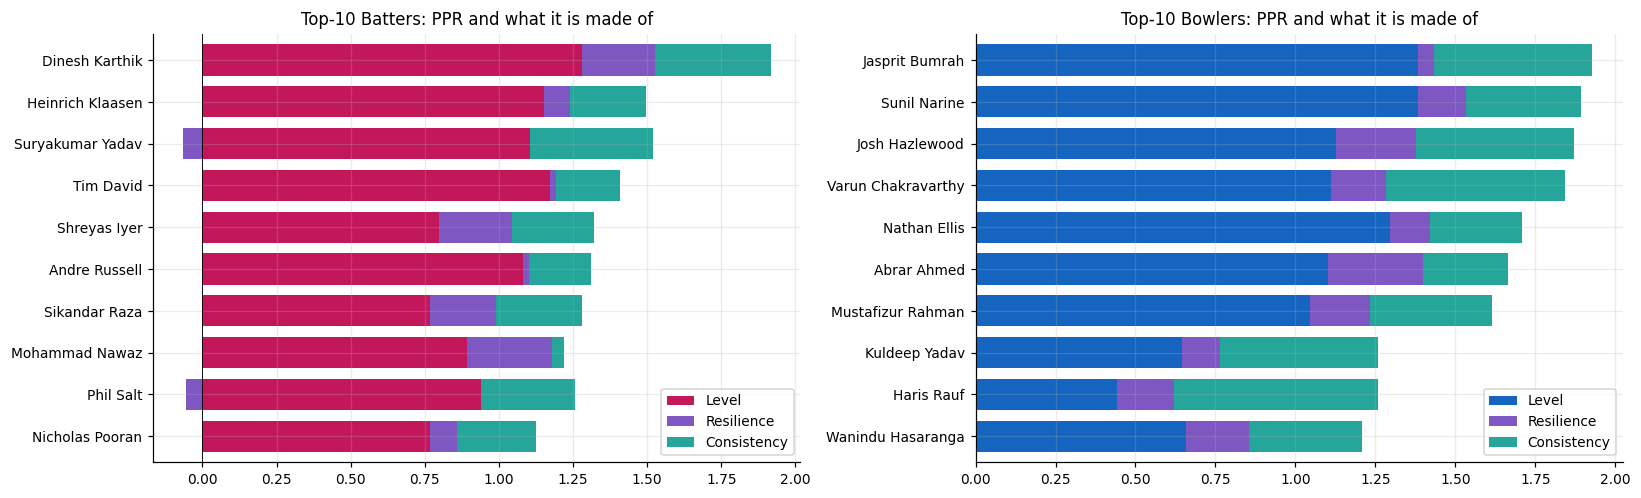

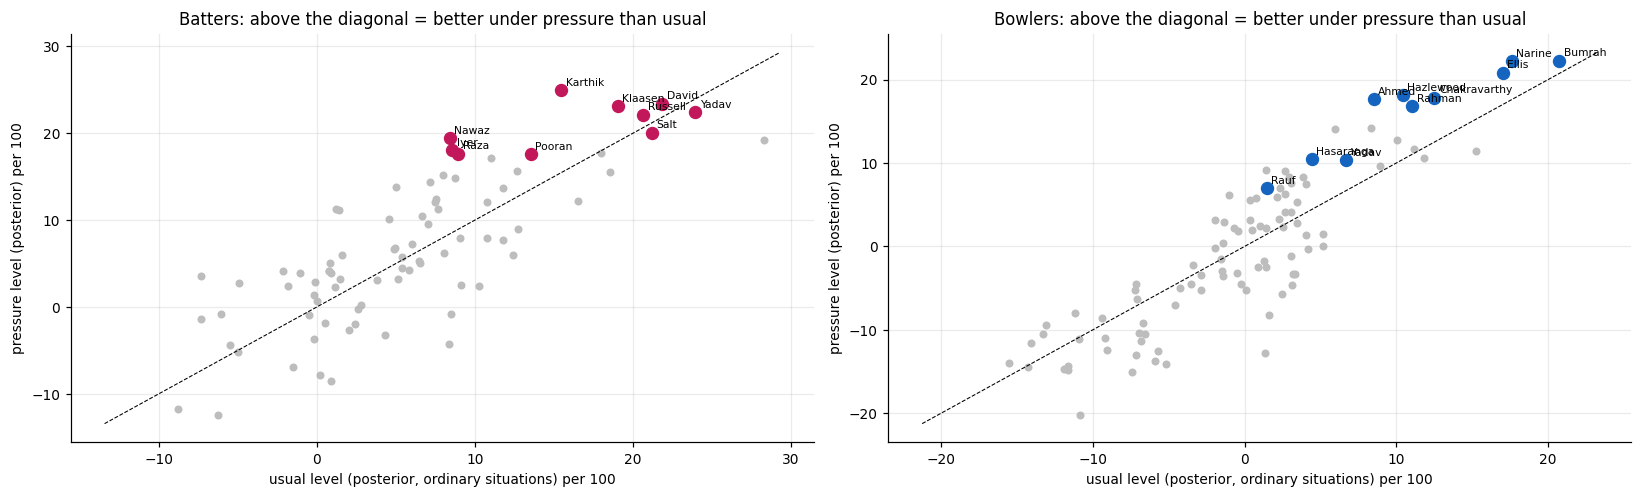

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, R, ttl, col in ((ax[0], RB, 'Batters', '#c2185b'), (ax[1], RW, 'Bowlers', '#1565c0')):
    t = R.head(10).iloc[::-1]; wts = WEIGHTS
    comp_ = pd.DataFrame({'Level': wts['level'] * t.z_level, 'Resilience': wts['resilience'] * t.z_resil, 'Consistency': wts['consistency'] * t.z_cons}); comp_.index = t.player
    comp_.plot.barh(stacked=True, ax=a, color=['#c2185b', '#7e57c2', '#26a69a'] if ttl == 'Batters' else ['#1565c0', '#7e57c2', '#26a69a'], width=.75)
    a.set_title(f'Top-10 {ttl}: PPR and what it is made of'); a.axvline(0, color='k', lw=.6); a.set_ylabel('')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, R, M, ttl, col in ((ax[0], RB, MB, 'Batters', '#c2185b'), (ax[1], RW, MW, 'Bowlers', '#1565c0')):
    e = M[(M.n_hp >= MIN_HP_BALLS) & (M.ap >= MIN_PA)]; a.scatter(e.usual * 100, e.level * 100, s=18, color='#bdbdbd')
    t = R.head(10); a.scatter(t.usual * 100, t.level * 100, s=60, color=col, zorder=3)
    for pid, r in t.iterrows(): a.annotate(r.player.split()[-1], (r.usual * 100, r.level * 100), fontsize=7, xytext=(3, 3), textcoords='offset points')
    lim = [min(e.usual.min(), e.level.min()) * 100 - 1, max(e.usual.max(), e.level.max()) * 100 + 1]; a.plot(lim, lim, 'k--', lw=.7)
    a.set_xlabel('usual level (posterior, ordinary situations) per 100'); a.set_ylabel('pressure level (posterior) per 100'); a.set_title(f'{ttl}: above the diagonal = better under pressure than usual')
plt.tight_layout(); plt.show()

# 10. Reliability: how much should we trust these ranks?

Four independent checks, all on the same code path as the main ranking:

1. **Match-level bootstrap** (300 resamples of matches): how often does each player stay in the top 10, and what is his rank range?
2. **Split-half persistence**: is pressure performance a *repeatable* skill? Random halves of the matches are rated separately and the two ratings are correlated.
3. **Alternative pressure definitions** and **alternative weights**: do the leaders survive a different definition of "high pressure" or a different composite?
4. **Cross-competition and cross-innings consistency**: do the leaders deliver in the IPL *and* in T20Is, and when chasing *and* when setting a target?

bootstrap done in 29s


### Bootstrap stability: batters (top 15)

,player,PPR,top10_freq,rank_median,rank_p05,rank_p95
rank,,,,,,
1,Dinesh Karthik,1.917,0.727,5.000,1.000,32.000
2,Heinrich Klaasen,1.497,0.557,9.000,1.000,40.000
3,Suryakumar Yadav,1.454,0.547,9.500,1.000,36.100
4,Tim David,1.408,0.523,9.000,1.000,35.000
5,Shreyas Iyer,1.319,0.470,11.000,1.000,45.050
6,Andre Russell,1.309,0.457,12.000,1.000,45.100
7,Sikandar Raza,1.280,0.457,12.000,2.000,43.050
8,Mohammad Nawaz,1.218,0.437,13.000,1.000,51.050
9,Phil Salt,1.201,0.413,13.000,2.000,41.000


### Bootstrap stability: bowlers (top 15)

,player,PPR,top10_freq,rank_median,rank_p05,rank_p95
rank,,,,,,
1,Jasprit Bumrah,1.927,0.730,6.000,1.000,27.000
2,Sunil Narine,1.894,0.700,6.000,1.000,27.050
3,Josh Hazlewood,1.871,0.670,6.000,1.000,28.000
4,Varun Chakravarthy,1.844,0.657,7.000,1.000,31.050
5,Nathan Ellis,1.709,0.577,9.000,1.000,33.000
6,Abrar Ahmed,1.666,0.550,8.500,1.000,37.000
7,Mustafizur Rahman,1.614,0.567,10.000,1.950,31.050
8,Kuldeep Yadav,1.259,0.377,14.000,2.000,44.050
9,Haris Rauf,1.258,0.400,14.000,1.950,46.050


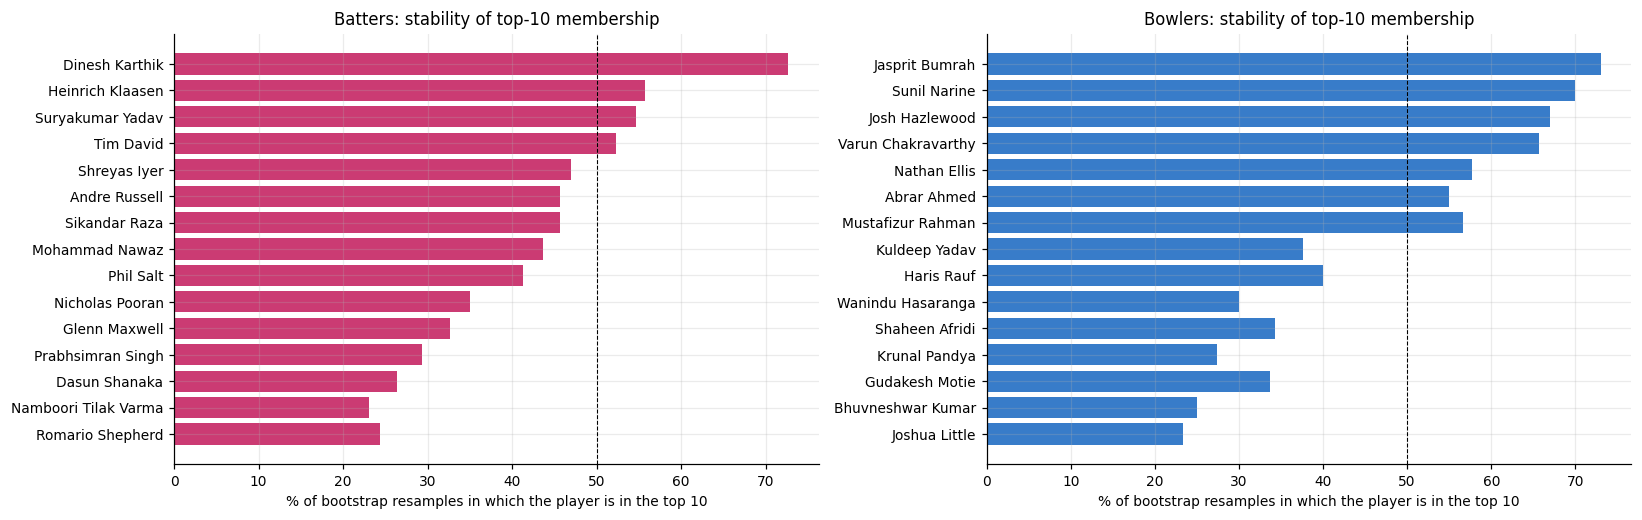

In [35]:
rng = np.random.default_rng(SEED)
def bootstrap(P, pr, elig_ids, n_boot=N_BOOT):
    matches = P.match_id.unique(); ranks = {}
    Pe = P[P.pid.isin(elig_ids)]
    for b_ in range(n_boot):
        cnt = np.bincount(rng.integers(0, len(matches), len(matches)), minlength=len(matches)); mw = pd.Series(cnt, index=matches)
        S = sums(Pe, mw); S = S[S.n_hp > 0]; t = metrics(S, pr); r = rate(t, pd.Series(True, index=t.index))
        for pid, rk in r['rank'].items(): ranks.setdefault(pid, []).append(rk)
    R_ = pd.DataFrame({pid: pd.Series(v) for pid, v in ranks.items()})
    return pd.DataFrame({'top10_freq': (R_ <= 10).mean(), 'median_rank': R_.median(), 'rank_p05': R_.quantile(.05), 'rank_p95': R_.quantile(.95)})
t0 = time.time()
bsB = bootstrap(PB, hpB, RB.index); bsW = bootstrap(PW, hpW, RW.index)
print(f'bootstrap done in {time.time() - t0:.0f}s')
for R, bs in ((RB, bsB), (RW, bsW)):
    R['top10_freq'] = bs.top10_freq.reindex(R.index); R['rank_median'] = bs.median_rank.reindex(R.index); R['rank_p05'] = bs.rank_p05.reindex(R.index); R['rank_p95'] = bs.rank_p95.reindex(R.index)
cols = ['player', 'rank', 'PPR', 'top10_freq', 'rank_median', 'rank_p05', 'rank_p95']
display(Markdown('### Bootstrap stability: batters (top 15)')); display(RB[cols].head(15).set_index('rank'))
display(Markdown('### Bootstrap stability: bowlers (top 15)')); display(RW[cols].head(15).set_index('rank'))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for a, R, ttl, col in ((ax[0], RB, 'Batters', '#c2185b'), (ax[1], RW, 'Bowlers', '#1565c0')):
    t = R.head(15).iloc[::-1]; a.barh(t.player, t.top10_freq * 100, color=col, alpha=.85); a.axvline(50, color='k', ls='--', lw=.7)
    a.set_xlabel('% of bootstrap resamples in which the player is in the top 10'); a.set_title(f'{ttl}: stability of top-10 membership')
plt.tight_layout(); plt.show()

In [36]:
def half_corr(P, hps, seeds=30, minn=40):
    matches = P.match_id.unique(); res = {k: [] for k in ('raw pressure level (unshrunk)', 'LEVEL (posterior)', 'usual level (posterior)', 'resilience (posterior)', 'consistency', 'WPA per ball (descriptive)', 'PPR')}; nn = []
    for s in range(seeds):
        rg = np.random.default_rng(100 + s); m1 = rg.choice(matches, len(matches) // 2, replace=False); w1 = pd.Series(np.isin(matches, m1).astype(float), index=matches)
        a_, b_ = metrics(sums(P, w1), hps), metrics(sums(P, 1 - w1), hps)
        k = [i for i in a_.index if a_.n_hp[i] >= minn and b_.n_hp.get(i, 0) >= minn and a_.ap[i] >= 5 and b_.ap.get(i, 0) >= 5]; a_, b_ = a_.loc[k], b_.loc[k]; nn.append(len(k))
        sp_ = lambda c: spearmanr(a_[c], b_[c])[0]
        ra, rb_ = rate(a_, pd.Series(True, index=a_.index)), rate(b_, pd.Series(True, index=b_.index))
        for nm, v in (('raw pressure level (unshrunk)', sp_('raw_level')), ('LEVEL (posterior)', sp_('level')), ('usual level (posterior)', sp_('usual')), ('resilience (posterior)', sp_('resilience')),
                      ('consistency', sp_('consistency')), ('WPA per ball (descriptive)', sp_('wpa_100')), ('PPR', spearmanr(ra.PPR, rb_.PPR.reindex(ra.index))[0])): res[nm].append(v)
    return pd.Series({k: np.mean(v) for k, v in res.items()}), np.mean(nn)
hb, nb_ = half_corr(PB, hpB); hw, nw_ = half_corr(PW, hpW)
sp = pd.DataFrame({'batters': hb, 'bowlers': hw}); sp.loc['players per half-pair (avg)'] = [nb_, nw_]
display(Markdown('### Split-half rank correlation (Spearman, mean of 30 random splits of the matches; players with >= 40 HP balls in each half)'))
display(sp.round(2))
print('Spearman-Brown full-sample reliability of PPR: batters %.2f, bowlers %.2f' % (2 * hb['PPR'] / (1 + hb['PPR']), 2 * hw['PPR'] / (1 + hw['PPR'])))

md = mm.set_index('match_id').match_date; med = md.median(); early = md[md <= med].index
def chrono(P, hps):
    mu_ = P.match_id.unique(); w1 = pd.Series(np.isin(mu_, early).astype(float), index=mu_)
    a_, b_ = metrics(sums(P, w1), hps), metrics(sums(P, 1 - w1), hps); k = [i for i in a_.index if a_.n_hp[i] >= 40 and b_.n_hp.get(i, 0) >= 40]
    return spearmanr(a_.loc[k].level, b_.loc[k].level)[0], len(k)
print('Chronological split (before vs after %s): LEVEL rank correlation batters %.2f (n=%d), bowlers %.2f (n=%d)' % ((med.date(),) + chrono(PB, hpB) + chrono(PW, hpW)))

### Split-half rank correlation (Spearman, mean of 30 random splits of the matches; players with >= 40 HP balls in each half)

,batters,bowlers
raw pressure level (unshrunk),-0.040,0.110
LEVEL (posterior),0.130,0.250
usual level (posterior),0.240,0.290
resilience (posterior),-0.060,-0.000
consistency,0.090,0.050
WPA per ball (descriptive),0.040,0.080
PPR,0.070,0.190
players per half-pair (avg),103.970,118.300


Spearman-Brown full-sample reliability of PPR: batters 0.13, bowlers 0.32
Chronological split (before vs after 2024-05-07): LEVEL rank correlation batters 0.05 (n=94), bowlers 0.23 (n=104)


In [37]:
# alternative pressure definitions
d['hp_g25']  = d.pi_global.rank(pct=True) >= 0.75
d['hp_in20'] = d.pi_pct_in >= 0.80; d['hp_in30'] = d.pi_pct_in >= 0.70; d['hp_in15'] = d.pi_pct_in >= 0.85
t1 = d.balls_left <= 36; t2 = (d.innings == 2) & d.rrr.between(8.5, 15) & (d.balls_left <= 72); t3 = d.wkts >= 5
d['hp_rule'] = (t1 & t2) | (t1 & t3) | (t2 & t3); d['w_one'] = 1.0
print('share of deliveries flagged HP -> rule-based (no model):', round(d.hp_rule.mean() * 100, 1), '% | overlap with PI-based HP:', round((d.hp_rule & d.hp).sum() / d.hp_rule.sum() * 100, 1), '% of rule-based HP deliveries are PI-HP')
variants = {'BASE: PI top 25% within innings': ('hp', 'w'), 'PI top 20% within innings': ('hp_in20', 'w'), 'PI top 30% within innings': ('hp_in30', 'w'), 'PI top 15% within innings': ('hp_in15', 'w'),
            'PI top 25% global (all innings pooled)': ('hp_g25', 'w'), 'Rule-based pressure (no model, equal weights)': ('hp_rule', 'w_one')}
base_top = {'bat': set(RB.index[:10]), 'bowl': set(RW.index[:10])}; rows = []; altR = {}
for nm, (hc, wc) in variants.items():
    bd = d[d.bat_faced]
    Pb_ = agg_table(bd, 'striker_id', 'r_bat', 'k_bat', 'wpa_bat', hc, wc); Pw_ = agg_table(d, 'bowler_id', 'r_bowl', 'k_bowl', 'wpa_bowl', hc, wc)
    Sb_, Sw_ = sums(Pb_), sums(Pw_); Mb_, Mw_ = metrics(Sb_, fit_all(Sb_)), metrics(Sw_, fit_all(Sw_))
    Rb_ = rate(Mb_, (Mb_.n_hp >= MIN_HP_BALLS) & (Mb_.ap >= MIN_PA)); Rw_ = rate(Mw_, (Mw_.n_hp >= MIN_HP_BALLS) & (Mw_.ap >= MIN_PA)); altR[nm] = (Rb_, Rw_)
    ib = [i for i in RB.index if i in Rb_.index]; iw = [i for i in RW.index if i in Rw_.index]
    rows.append({'definition': nm, 'HP share %': d[hc].mean() * 100, 'batters eligible': len(Rb_), 'bat top-10 overlap': len(base_top['bat'] & set(Rb_.index[:10])), 'bat Spearman vs base': spearmanr(RB.loc[ib].PPR, Rb_.loc[ib].PPR)[0],
                 'bowlers eligible': len(Rw_), 'bowl top-10 overlap': len(base_top['bowl'] & set(Rw_.index[:10])), 'bowl Spearman vs base': spearmanr(RW.loc[iw].PPR, Rw_.loc[iw].PPR)[0]})
display(Markdown('### Robustness to the definition of pressure')); display(pd.DataFrame(rows).set_index('definition').round(2))


def freq(idx, k, which, kk=10):
    return pd.Series({i: np.mean([(i in altR[n][which].index[:kk]) for n in variants if n != list(variants)[0]]) for i in idx})
stay = pd.DataFrame({'batter': [canon[i] for i in RB.index[:10]], 'share of 5 alt. definitions with player in top 10': freq(RB.index[:10], 10, 0).values,
                     'bowler': [canon[i] for i in RW.index[:10]], 'share (bowlers)': freq(RW.index[:10], 10, 1).values}, index=np.arange(1, 11)); display(stay.round(2))

share of deliveries flagged HP -> rule-based (no model): 19.1 % | overlap with PI-based HP: 46.9 % of rule-based HP deliveries are PI-HP


### Robustness to the definition of pressure

,HP share %,batters eligible,bat top-10 overlap,bat Spearman vs base,bowlers eligible,bowl top-10 overlap,bowl Spearman vs base
definition,,,,,,,
BASE: PI top 25% within innings,25.000,82,10,1.000,97,10,1.000
PI top 20% within innings,20.000,65,6,0.940,88,7,0.960
PI top 30% within innings,30.000,102,9,0.950,113,7,0.960
PI top 15% within innings,15.000,43,7,0.930,66,6,0.880
PI top 25% global (all innings pooled),25.000,55,7,0.780,83,4,0.880
"Rule-based pressure (no model, equal weights)",19.140,60,4,0.740,89,6,0.710


,batter,share of 5 alt. definitions with player in top 10,bowler,share (bowlers)
1,Dinesh Karthik,0.800,Jasprit Bumrah,1.000
2,Heinrich Klaasen,0.800,Sunil Narine,1.000
3,Suryakumar Yadav,0.600,Josh Hazlewood,0.800
4,Tim David,0.800,Varun Chakravarthy,1.000
5,Shreyas Iyer,0.600,Nathan Ellis,0.600
6,Andre Russell,0.800,Abrar Ahmed,0.600
7,Sikandar Raza,0.200,Mustafizur Rahman,0.800
8,Mohammad Nawaz,0.600,Kuldeep Yadav,0.200
9,Phil Salt,0.400,Haris Rauf,0.000
10,Nicholas Pooran,1.000,Wanindu Hasaranga,0.000


In [38]:
# alternative weightings
comp_cols = ['z_level', 'z_resil', 'z_cons']
alt_w = {'BASE (60/15/25)': (.60, .15, .25), 'Equal weights': (1/3, 1/3, 1/3), 'Level only': (1, 0, 0), 'Consistency-heavy (30/10/60)': (.30, .10, .60),
         'No resilience (70/0/30)': (.70, 0, .30), 'Resilience-heavy (40/40/20)': (.40, .40, .20)}
rows = []
for nm, w in alt_w.items():
    rb_ = (RB[comp_cols] * np.array(w)).sum(axis=1).sort_values(ascending=False); rw_ = (RW[comp_cols] * np.array(w)).sum(axis=1).sort_values(ascending=False)
    rows.append({'weights': nm, 'bat top-10 overlap': len(set(rb_.index[:10]) & base_top['bat']), 'bat Spearman': spearmanr(RB.PPR, rb_.reindex(RB.index))[0],
                 'bowl top-10 overlap': len(set(rw_.index[:10]) & base_top['bowl']), 'bowl Spearman': spearmanr(RW.PPR, rw_.reindex(RW.index))[0]})
display(Markdown('### Robustness to the component weights')); display(pd.DataFrame(rows).set_index('weights').round(2))
rg = np.random.default_rng(SEED); W = rg.dirichlet(np.ones(3), 2000)
fb = pd.Series(0.0, index=RB.index); fw = pd.Series(0.0, index=RW.index)
for w in W:
    fb[(RB[comp_cols] * w).sum(axis=1).nlargest(10).index] += 1; fw[(RW[comp_cols] * w).sum(axis=1).nlargest(10).index] += 1
RB['top10_weightfreq'] = fb / len(W); RW['top10_weightfreq'] = fw / len(W)
print('Share of 2,000 random weight vectors (Dirichlet(1,1,1)) that keep each player in the top 10:')
display(pd.DataFrame({'batter': RB.player.head(12).values, 'freq': RB.top10_weightfreq.head(12).values, 'bowler': RW.player.head(12).values, 'freq ': RW.top10_weightfreq.head(12).values}, index=np.arange(1, 13)).round(2))

### Robustness to the component weights

,bat top-10 overlap,bat Spearman,bowl top-10 overlap,bowl Spearman
weights,,,,
BASE (60/15/25),10,1.000,10,1.000
Equal weights,7,0.960,9,0.970
Level only,8,0.940,7,0.970
Consistency-heavy (30/10/60),8,0.930,9,0.940
No resilience (70/0/30),9,0.990,9,0.990
Resilience-heavy (40/40/20),6,0.950,9,0.970


Share of 2,000 random weight vectors (Dirichlet(1,1,1)) that keep each player in the top 10:


,batter,freq,bowler,freq
1,Dinesh Karthik,1.000,Jasprit Bumrah,0.740
2,Heinrich Klaasen,0.690,Sunil Narine,0.910
3,Suryakumar Yadav,0.560,Josh Hazlewood,1.000
4,Tim David,0.450,Varun Chakravarthy,0.990
5,Shreyas Iyer,1.000,Nathan Ellis,0.590
6,Andre Russell,0.360,Abrar Ahmed,0.950
7,Sikandar Raza,1.000,Mustafizur Rahman,1.000
8,Mohammad Nawaz,0.680,Kuldeep Yadav,0.540
9,Phil Salt,0.370,Haris Rauf,0.720
10,Nicholas Pooran,0.460,Wanindu Hasaranga,0.670


### Top-10 batters: runs above expected per 100 HP balls, by competition and innings

HP balls         value /100b            HP balls               value /100b              
                      IPL    T20I         IPL    T20I inn 1 (set) inn 2 (chase) inn 1 (set) inn 2 (chase)
Dinesh Karthik    225.000 109.000      44.200  29.100     258.000        76.000      32.300        54.100
Heinrich Klaasen  339.000  39.000      19.700  60.900     256.000       122.000      14.800        38.100
Suryakumar Yadav  366.000 211.000      12.600  46.200     236.000       341.000      28.900        20.500
Tim David         242.000 262.000      12.100  43.200     254.000       250.000      19.800        29.300
Shreyas Iyer      346.000 110.000      40.300  -5.800     188.000       268.000      22.500        32.000
Andre Russell     242.000  49.000      33.200 -27.500     208.000        83.000      47.100       -14.700
Sikandar Raza      51.000 253.000      10.300  24.800     115.000       189.000      26.400        19.100
Mohammad Nawaz        NaN 225.000         NaN  36.300     144.000        81.000      18.300        57.800
Phil Salt          69.000 140.000      25.200  21.600      53.000       156.000      20.800        23.300
Nicholas Pooran   359.000 202.000      46.700 -20.400     298.000       263.000       1.400        41.200

### Top-10 bowlers: runs saved per 100 HP deliveries, by competition and innings

HP balls         value /100b                  HP balls                       value /100b               
                        IPL    T20I         IPL   T20I inn 1 (bowl first) inn 2 (defend) inn 1 (bowl first) inn 2 (defend)
Jasprit Bumrah      350.000  92.000      29.600 17.800            270.000        172.000             43.600          9.600
Sunil Narine        394.000     NaN      32.400    NaN            147.000        247.000             32.300         32.400
Josh Hazlewood      255.000 119.000      28.500 59.100            187.000        187.000             14.600         53.700
Varun Chakravarthy  288.000 107.000      17.500 64.200            149.000        246.000             33.600         28.100
Nathan Ellis        113.000 186.000      29.300 27.100            165.000        134.000             33.300         23.200
Abrar Ahmed             NaN 198.000         NaN 39.400             86.000        112.000             62.200         24.000
Mustafizur Rahman   139.000 364.000      -2.700 24.300            346.000        157.000             28.600          0.000
Kuldeep Yadav       468.000 109.000      20.700 -2.200            335.000        242.000             18.500         13.600
Haris Rauf              NaN 333.000         NaN 15.400            149.000        184.000             44.700         -3.400
Wanindu Hasaranga   305.000 233.000      10.200 24.400            258.000        280.000             15.700         16.800

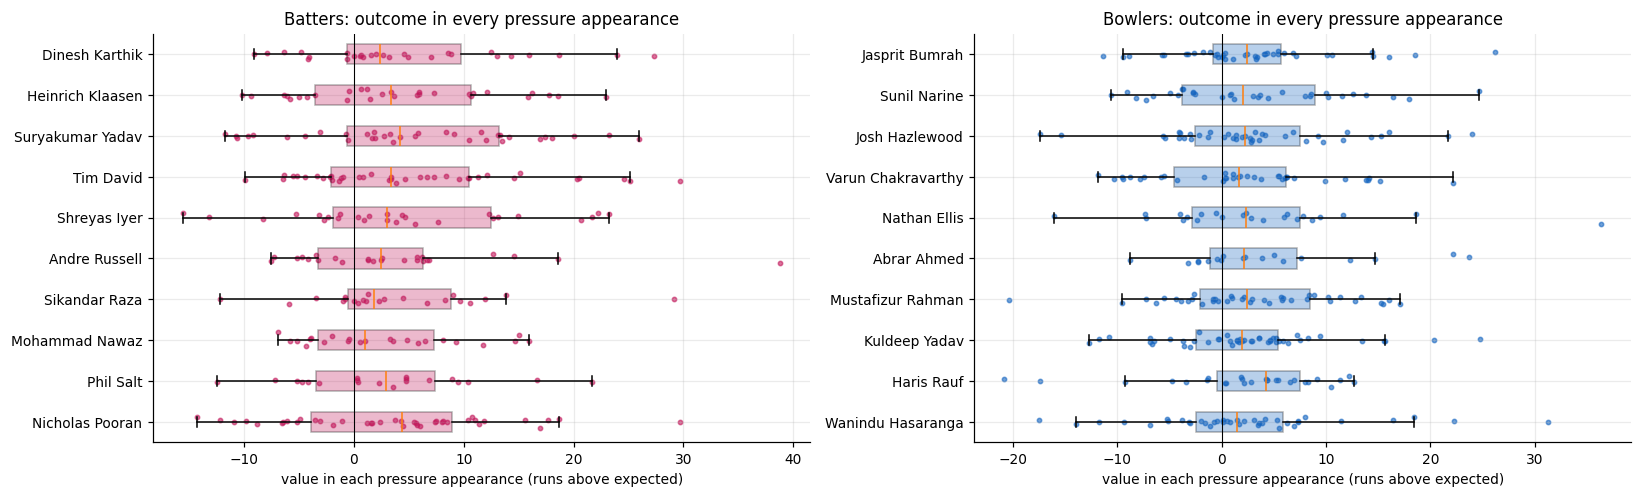

In [39]:
# IPL vs T20I and 1st vs 2nd innings: do the leaders deliver everywhere?
def split_table(df, pid, bvc, ids, by):
    h = df[df.hp & df[pid].isin(ids)]
    g = h.groupby([pid, by]).apply(lambda x: pd.Series({'n': len(x), 'v': np.average(x[bvc], weights=x.w) * 100}))
    n = g['n'].unstack(); v = g['v'].unstack(); out = pd.concat({'HP balls': n, 'value /100b': v}, axis=1); out.index = [canon[i] for i in out.index]; return out
display(Markdown('### Top-10 batters: runs above expected per 100 HP balls, by competition and innings'))
tb_ = split_table(bat_df, 'striker_id', 'bv_bat', topB, 'comp_type'); tb2 = split_table(bat_df, 'striker_id', 'bv_bat', topB, 'innings')
display(pd.concat([tb_, tb2.rename(columns={1: 'inn 1 (set)', 2: 'inn 2 (chase)'})], axis=1).reindex([canon[i] for i in topB]).round(1))
display(Markdown('### Top-10 bowlers: runs saved per 100 HP deliveries, by competition and innings'))
tw_ = split_table(d, 'bowler_id', 'bv_bowl', topW, 'comp_type'); tw2 = split_table(d, 'bowler_id', 'bv_bowl', topW, 'innings')
display(pd.concat([tw_, tw2.rename(columns={1: 'inn 1 (bowl first)', 2: 'inn 2 (defend)'})], axis=1).reindex([canon[i] for i in topW]).round(1))

# appearance-by-appearance consistency of the leaders
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, P_, top, ttl, col in ((ax[0], PB, topB, 'Batters', '#c2185b'), (ax[1], PW, topW, 'Bowlers', '#1565c0')):
    ap_ = P_[(P_.ap == 1) & P_.pid.isin(top)]
    data = [ap_[ap_.pid == p].bv_hp_u.values for p in top][::-1]
    a.boxplot(data, vert=False, showfliers=False, patch_artist=True, boxprops=dict(facecolor=col, alpha=.3))
    for i, v in enumerate(data, start=1): a.scatter(v, np.random.default_rng(i).normal(i, .06, len(v)), s=8, color=col, alpha=.6)
    a.set_yticklabels([canon[p] for p in top][::-1]); a.axvline(0, color='k', lw=.7); a.set_xlabel('value in each pressure appearance (runs above expected)'); a.set_title(f'{ttl}: outcome in every pressure appearance')
plt.tight_layout(); plt.show()

# 11. Limitations and where the model is less certain

1. **Pressure performance is only weakly persistent.** Split-half rank correlations of the final rating are ≈0.13 (batters) and ≈0.17 (bowlers), i.e. a Spearman-Brown full-sample reliability of ≈0.2-0.3. Raw pressure numbers are close to pure noise (batters ≈0.00); the hierarchical model roughly doubles the persistence by borrowing strength from ordinary situations, but ranks 1-10 are still **probabilistic**: bootstrap top-10 membership is 30-70 %, not 95 %. Our rankings are the best *posterior estimates*, not certainties; differences between neighbouring ranks are mostly within noise.
2. **The pressure-specific uplift (resilience) is the weakest component** (split-half ≈ −0.1 to 0.04). This is consistent with the wider "clutch hitting" literature: most of what looks like clutch skill is general ability plus luck. We therefore give it a small weight and report it transparently instead of hiding it.
3. **Win-probability model.** The 1st-innings WP model is weak (AUC ≈ 0.70) because a total is not yet set; leverage there is a lower-confidence estimate. That is why pressure is ranked *within* each innings and why a global-threshold variant is reported.
4. **Opposition quality in T20Is.** Elo-based adjustment is coarse (few matches per associate nation, no home/venue-strength term). Leaders whose pressure value comes mainly from T20Is against weaker sides (see the IPL/T20I split) deserve more caution.
5. **Role and attribution.** Batters are compared with others of the *same batting position*; run-outs of the non-striker, partnership effects, captaincy/field-placing decisions and bowlers' support (catching) are not modelled. Wicket value (λ) comes from first-innings run expectancy and is applied to both innings.
6. **Exclusions.** Rain-affected (revised-target) matches, super-over matches and non-IPL/T20I competitions are dropped (section 3); players mostly appearing there have less data. No data after the file's last match is used.
7. **Eligibility** (≥ 100 HP deliveries and ≥ 15 pressure appearances) excludes genuine specialists with small samples (e.g. death-overs only players).

**Possible extensions**: ball-level fielding/pitch information, batter-vs-bowler matchup effects, a Bayesian bootstrap for full posterior rank distributions, and tracking pressure performance within a season.

# 12. Final submission

In [40]:
def final(R, hp_):
    t = R.head(10)[['player', 'team', 'n_hp', 'ap', 'level', 'resilience', 'consistency', 'PPR', 'top10_freq', 'rank_p05', 'rank_p95']].copy()
    t.insert(0, 'player_id', t.index); t.index = np.arange(1, 11); t.index.name = 'Rank'
    t['level'] = t.level * 100; t['resilience'] = t.resilience * 100
    t.columns = ['player_id', 'Player (use this name in the dropdown)', 'Team(s)', 'HP balls', 'pressure appearances', 'level /100 balls', 'resilience /100', 'consistency', 'PPR', 'bootstrap top-10 freq', 'rank 5th pct', 'rank 95th pct']; return t
FB, FW = final(RB, hpB), final(RW, hpW)
display(Markdown('## Top 10 batters under pressure (Rank 1 → 10)')); display(FB.round(2))
display(Markdown('## Top 10 bowlers under pressure (Rank 1 → 10)')); display(FW.round(2))
FB.to_csv(OUT_DIR / 'top10_batters_under_pressure.csv'); FW.to_csv(OUT_DIR / 'top10_bowlers_under_pressure.csv')
RB.drop(columns=['wpa_hp']).to_csv(OUT_DIR / 'all_eligible_batters_ratings.csv'); RW.drop(columns=['wpa_hp']).to_csv(OUT_DIR / 'all_eligible_bowlers_ratings.csv')
d[['match_id', 'innings', 'overid', 'innings_ball_num', 'wp', 'pi_global', 'hp']].to_csv(OUT_DIR / 'delivery_pressure_index.csv.gz', index=False)
print('Saved to', OUT_DIR.resolve(), ':', sorted(p.name for p in OUT_DIR.iterdir()))
dups = [canon[i] for i in list(FB.player_id) + list(FW.player_id) if (canon == canon[i]).sum() > 1]
print('Players sharing a name with another player id (check the dropdown carefully):', dups or 'none')

## Top 10 batters under pressure (Rank 1 → 10)

,player_id,Player (use this name in the dropdown),Team(s),HP balls,pressure appearances,level /100 balls,resilience /100,consistency,PPR,bootstrap top-10 freq,rank 5th pct,rank 95th pct
Rank,,,,,,,,,,,,
1,143,Dinesh Karthik,India / Royal Challengers Bengaluru,334.000,28.000,24.970,9.500,0.660,1.920,0.730,1.000,32.000
2,4260,Heinrich Klaasen,South Africa / Sunrisers Hyderabad,378.000,29.000,23.100,4.060,0.620,1.500,0.560,1.000,40.000
3,1699,Suryakumar Yadav,India / Mumbai Indians,577.000,35.000,22.450,-1.490,0.670,1.450,0.550,1.000,36.100
4,6396,Tim David,Australia / Mumbai Indians,504.000,38.000,23.400,1.550,0.610,1.410,0.520,1.000,35.000
5,3647,Shreyas Iyer,India / Kolkata Knight Riders,456.000,27.000,18.080,9.520,0.630,1.320,0.470,1.000,45.050
6,1318,Andre Russell,West Indies / Kolkata Knight Riders,291.000,25.000,22.140,1.470,0.610,1.310,0.460,1.000,45.100
7,2984,Sikandar Raza,Zimbabwe / Punjab Kings,304.000,22.000,17.650,8.720,0.630,1.280,0.460,2.000,43.050
8,2490,Mohammad Nawaz,Pakistan,225.000,23.000,19.430,11.020,0.550,1.220,0.440,1.000,51.050
9,5553,Phil Salt,England / Royal Challengers Bengaluru,209.000,20.000,20.090,-1.100,0.640,1.200,0.410,2.000,41.000


## Top 10 bowlers under pressure (Rank 1 → 10)

,player_id,Player (use this name in the dropdown),Team(s),HP balls,pressure appearances,level /100 balls,resilience /100,consistency,PPR,bootstrap top-10 freq,rank 5th pct,rank 95th pct
Rank,,,,,,,,,,,,
1,2933,Jasprit Bumrah,India / Mumbai Indians,442.000,39.000,22.260,1.520,0.630,1.930,0.730,1.000,27.000
2,781,Sunil Narine,Kolkata Knight Riders,394.000,32.000,22.250,4.640,0.590,1.890,0.700,1.000,27.050
3,830,Josh Hazlewood,Australia / Royal Challengers Bengaluru,374.000,39.000,18.130,7.710,0.630,1.870,0.670,1.000,28.000
4,6256,Varun Chakravarthy,India / Kolkata Knight Riders,395.000,36.000,17.850,5.340,0.650,1.840,0.660,1.000,31.050
5,7920,Nathan Ellis,Australia / Punjab Kings,299.000,23.000,20.860,3.850,0.570,1.710,0.580,1.000,33.000
6,5979,Abrar Ahmed,Pakistan,198.000,18.000,17.700,9.200,0.560,1.670,0.550,1.000,37.000
7,4373,Mustafizur Rahman,Bangladesh / Delhi Capitals,503.000,40.000,16.800,5.740,0.590,1.610,0.570,1.950,31.050
8,3644,Kuldeep Yadav,India / Delhi Capitals,577.000,47.000,10.330,3.660,0.630,1.260,0.380,2.000,44.050
9,7364,Haris Rauf,Pakistan,333.000,27.000,7.010,5.550,0.670,1.260,0.400,1.950,46.050


Saved to /content/drive/MyDrive/SupeRR_Selector/outputs : ['all_eligible_batters_ratings.csv', 'all_eligible_bowlers_ratings.csv', 'delivery_pressure_index.csv.gz', 'top10_batters_under_pressure.csv', 'top10_bowlers_under_pressure.csv']
Players sharing a name with another player id (check the dropdown carefully): none


In [41]:
sw1 = d.groupby('innings').apply(lambda x: x.loc[x.hp, 'abs_dwp'].sum() / x.abs_dwp.sum()).mul(100).round(0).to_dict()
ranks_b = ', '.join(f'{i}. {p}' for i, p in zip(range(1, 11), FB.iloc[:, 1])); ranks_w = ', '.join(f'{i}. {p}' for i, p in zip(range(1, 11), FW.iloc[:, 1]))
display(Markdown(f"""# 13. Methodology report (summary for the Unstop upload)

**Pressure definition.** A delivery's *Pressure Index* is the expected size of the swing in the batting team's win probability that the delivery can produce (leverage). Win probability comes from a smooth gradient-boosted model of innings, balls left, wickets, runs, required rate, runs needed, team-strength gap (pre-match Elo), venue par and competition (out-of-fold AUC ≈ 0.70 first innings, ≈ 0.89 second innings). A delivery is *high-pressure* when it is in the top quartile of PI within its innings. These deliveries hold {sw1} % (innings 1, 2) of all win-probability movement while being 25 % of deliveries, and differ visibly from ordinary ones in wicket rate and run rate (section 6.3). It encodes required rate, wickets in hand, balls remaining, innings stage and closeness *jointly* instead of with hand-set weights.

**Performance measurement.** Each delivery is compared with the expected outcome for that exact situation (baselines that know phase, target, wickets, venue, competition, opposition strength, batting position and pace/spin, but not the player): batter = runs above expected minus λ-priced wickets above expected; bowler = runs saved plus λ-priced wickets above expected. Player *baselines* = the same value on his ordinary (non-HP) deliveries.

**Rating logic.** A hierarchical empirical-Bayes model (usual ability + pressure uplift, separately for the runs part and the wicket part, cluster-robust variances) gives each player a posterior pressure *Level*, a *Resilience* (pressure minus usual) and, from his pressure appearances, a *Consistency* rate. PPR = 0.60 z(Level) + 0.15 z(Resilience) + 0.25 z(Consistency).

**Fair comparison.** Shrinkage handles sample size; eligibility = ≥ {MIN_HP_BALLS} HP deliveries and ≥ {MIN_PA} pressure appearances; context and opposition strength enter the baselines; IPL and T20I are pooled with a competition flag, Elo and venue par, and every leader is re-checked per competition and per innings (section 10).

**Final rankings.**
* Batters: {ranks_b}.
* Bowlers: {ranks_w}.

**Reliability.** Bootstrap, split-half and alternative-definition checks are in section 10; pressure performance is only partly persistent (split-half PPR correlation {hb['PPR']:.2f} batters / {hw['PPR']:.2f} bowlers), so rank differences inside the top 10 are small relative to uncertainty (section 11)."""))

# 13. Methodology report (summary for the Unstop upload)

**Pressure definition.** A delivery's *Pressure Index* is the expected size of the swing in the batting team's win probability that the delivery can produce (leverage). Win probability comes from a smooth gradient-boosted model of innings, balls left, wickets, runs, required rate, runs needed, team-strength gap (pre-match Elo), venue par and competition (out-of-fold AUC ≈ 0.70 first innings, ≈ 0.89 second innings). A delivery is *high-pressure* when it is in the top quartile of PI within its innings. These deliveries hold {1: 43.0, 2: 59.0} % (innings 1, 2) of all win-probability movement while being 25 % of deliveries, and differ visibly from ordinary ones in wicket rate and run rate (section 6.3). It encodes required rate, wickets in hand, balls remaining, innings stage and closeness *jointly* instead of with hand-set weights.

**Performance measurement.** Each delivery is compared with the expected outcome for that exact situation (baselines that know phase, target, wickets, venue, competition, opposition strength, batting position and pace/spin, but not the player): batter = runs above expected minus λ-priced wickets above expected; bowler = runs saved plus λ-priced wickets above expected. Player *baselines* = the same value on his ordinary (non-HP) deliveries.

**Rating logic.** A hierarchical empirical-Bayes model (usual ability + pressure uplift, separately for the runs part and the wicket part, cluster-robust variances) gives each player a posterior pressure *Level*, a *Resilience* (pressure minus usual) and, from his pressure appearances, a *Consistency* rate. PPR = 0.60 z(Level) + 0.15 z(Resilience) + 0.25 z(Consistency).

**Fair comparison.** Shrinkage handles sample size; eligibility = ≥ 100 HP deliveries and ≥ 15 pressure appearances; context and opposition strength enter the baselines; IPL and T20I are pooled with a competition flag, Elo and venue par, and every leader is re-checked per competition and per innings (section 10).

**Final rankings.**
* Batters: 1. Dinesh Karthik, 2. Heinrich Klaasen, 3. Suryakumar Yadav, 4. Tim David, 5. Shreyas Iyer, 6. Andre Russell, 7. Sikandar Raza, 8. Mohammad Nawaz, 9. Phil Salt, 10. Nicholas Pooran.
* Bowlers: 1. Jasprit Bumrah, 2. Sunil Narine, 3. Josh Hazlewood, 4. Varun Chakravarthy, 5. Nathan Ellis, 6. Abrar Ahmed, 7. Mustafizur Rahman, 8. Kuldeep Yadav, 9. Haris Rauf, 10. Wanindu Hasaranga.

**Reliability.** Bootstrap, split-half and alternative-definition checks are in section 10; pressure performance is only partly persistent (split-half PPR correlation 0.07 batters / 0.19 bowlers), so rank differences inside the top 10 are small relative to uncertainty (section 11).